In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd
import numpy as np

In [4]:
import os

print(os.path.exists("/content/Dataset"))

False


In [5]:
%pip install torchxrayvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 74.0 MB/s eta 0:00:00


In [6]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

import tensorflow as tf
import torch
import torchvision
import torchxrayvision as xrv

from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.densenet import preprocess_input

print("TensorFlow:", tf.__version__)
print("Torch:", torch.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
Torch: 2.11.0+cu128
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
dataset_path = "/content/Dataset"

print("Dataset exists:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print(os.listdir(dataset_path))

Dataset exists: False


In [7]:
import os
import shutil
import time

DRIVE_DATASET = "/content/drive/MyDrive/AI_Pneumonia_Detection/Dataset"
LOCAL_DATASET = "/content/Dataset"

if not os.path.exists(LOCAL_DATASET):
    print("Copying dataset from Google Drive to Colab local storage...")
    start = time.time()

    shutil.copytree(DRIVE_DATASET, LOCAL_DATASET)

    elapsed = time.time() - start
    print(f"Dataset copied in {elapsed/60:.2f} minutes.")
else:
    print("Local dataset already exists.")

print("\nLocal dataset contents:")
print(os.listdir(LOCAL_DATASET))

Copying dataset from Google Drive to Colab local storage...
Dataset copied in 3.85 minutes.

Local dataset contents:
['test', 'train', 'val']


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

TRAIN_PATH = "/content/Dataset/train"
TEST_PATH = "/content/Dataset/test"

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0,
    validation_split=0.15,
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.10,
    horizontal_flip=True
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=SEED
)

validation_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=SEED
)

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255.0
)

test_generator = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

print("\n===== GENERATOR SUMMARY =====")
print("Class mapping:", train_generator.class_indices)
print("Training:", train_generator.samples)
print("Validation:", validation_generator.samples)
print("Test:", test_generator.samples)

Found 4457 images belonging to 2 classes.
Found 786 images belonging to 2 classes.
Found 640 images belonging to 2 classes.

===== GENERATOR SUMMARY =====
Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Training: 4457
Validation: 786
Test: 640


In [ ]:
import os
from PIL import Image
from collections import Counter

# Paths
DATASET_PATH = "/content/drive/MyDrive/AI_Pneumonia_Detection/Dataset"

splits = ["train", "test", "val"]
classes = ["NORMAL", "PNEUMONIA"]

# ---------- COUNT IMAGES ----------
print("===== DATASET SUMMARY =====\n")

for split in splits:
    print(f"--- {split.upper()} ---")

    total = 0

    for cls in classes:
        folder = os.path.join(DATASET_PATH, split, cls)

        files = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{cls}: {len(files)}")
        total += len(files)

    print(f"Total: {total}\n")


# ---------- CHECK CORRUPTED IMAGES ----------
print("===== IMAGE VALIDATION =====\n")

corrupted = []
image_sizes = Counter()

for split in splits:
    for cls in classes:
        folder = os.path.join(DATASET_PATH, split, cls)

        for filename in os.listdir(folder):
            if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
                continue

            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:
                    img.verify()

                # Re-open to get dimensions
                with Image.open(filepath) as img:
                    image_sizes[img.size] += 1

            except Exception:
                corrupted.append(filepath)

print("Corrupted images:", len(corrupted))

if corrupted:
    print("\nCorrupted files:")
    for f in corrupted[:20]:
        print(f)

print("\n===== IMAGE DIMENSIONS =====")
print("Unique dimensions:", len(image_sizes))

for size, count in image_sizes.most_common(10):
    print(f"{size}: {count} images")

===== DATASET SUMMARY =====

--- TRAIN ---
NORMAL: 1341
PNEUMONIA: 3902
Total: 5243

--- TEST ---
NORMAL: 234
PNEUMONIA: 406
Total: 640

--- VAL ---
NORMAL: 8
PNEUMONIA: 8
Total: 16

===== IMAGE VALIDATION =====

Corrupted images: 0

===== IMAGE DIMENSIONS =====
Unique dimensions: 4803
(1008, 704): 7 images
(1072, 648): 7 images
(1216, 872): 6 images
(992, 608): 6 images
(1080, 728): 6 images
(992, 592): 6 images
(1184, 792): 6 images
(1304, 968): 5 images
(1152, 664): 5 images
(1064, 760): 5 images


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

train_labels = train_generator.classes

classes = np.unique(train_labels)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("===== CLASS WEIGHTS =====")

for cls, weight in class_weights.items():
    name = "NORMAL" if cls == 0 else "PNEUMONIA"
    count = np.sum(train_labels == cls)

    print(f"{name}:")
    print(f"  Images: {count}")
    print(f"  Weight: {weight:.4f}")

print("\nClass weights:", class_weights)

===== CLASS WEIGHTS =====
NORMAL:
  Images: 1140
  Weight: 1.9548
PNEUMONIA:
  Images: 3317
  Weight: 0.6718

Class weights: {0: 1.9548245614035087, 1: 0.6718420259270426}


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.random.set_seed(42)

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import os

MODEL_DIR = "/content/drive/MyDrive/AI_Pneumonia_Detection/models"
os.makedirs(MODEL_DIR, exist_ok=True)

print("Model directory ready:", MODEL_DIR)

Model directory ready: /content/drive/MyDrive/AI_Pneumonia_Detection/models


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    os.path.join(MODEL_DIR, "cnn_baseline_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

cnn_history = cnn_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - accuracy: 0.6523 - loss: 0.6077 - precision: 0.8461 - recall: 0.6548
Epoch 1: val_loss improved from None to 0.32982, saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/cnn_baseline_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/cnn_baseline_best.keras
279/279 ━━━━━━━━━━━━━━━━━━━━ 123s 417ms/step - accuracy: 0.7741 - loss: 0.4458 - precision: 0.9167 - recall: 0.7661 - val_accuracy: 0.8575 - val_loss: 0.3298 - val_precision: 0.9937 - val_recall: 0.8137
Epoch 2/10
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 348ms/step - accuracy: 0.8899 - loss: 0.2786 - precision: 0.9677 - recall: 0.8829
Epoch 2: val_loss improved from 0.32982 to 0.22497, saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/cnn_baseline_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/cnn_baseline_best.keras
279/279 ━━━━━━━━━━━━━━━━━━━━ 113s 40

In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Get validation probabilities
val_probs = cnn_model.predict(validation_generator).ravel()

# True validation labels
val_true = validation_generator.classes

# Make sure probabilities and labels align
print("Validation samples:", len(val_true))
print("Predictions:", len(val_probs))

# Test thresholds from 0.10 to 0.90
thresholds = np.arange(0.10, 0.91, 0.01)

results = []

for threshold in thresholds:
    val_pred = (val_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_true, val_pred, labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(val_true, val_pred)
    precision = precision_score(val_true, val_pred, zero_division=0)
    recall = recall_score(val_true, val_pred, zero_division=0)
    f1 = f1_score(val_true, val_pred, zero_division=0)

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    results.append([
        threshold,
        accuracy,
        precision,
        recall,
        specificity,
        f1
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "f1"
    ]
)

# Best threshold according to F1
best_row = results_df.loc[results_df["f1"].idxmax()]

print("\nBest validation threshold:")
print(best_row)

50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 312ms/step
Validation samples: 786
Predictions: 786

Best validation threshold:
threshold      0.380000
accuracy       0.921120
precision      0.926591
recall         0.970940
specificity    0.776119
f1             0.948247
Name: 28, dtype: float64


In [ ]:
display(
    results_df.sort_values("f1", ascending=False).head(10)
)

,threshold,accuracy,precision,recall,specificity,f1
28,0.38,0.921120,0.926591,0.970940,0.776119,0.948247
33,0.43,0.921120,0.933665,0.962393,0.800995,0.947811
29,0.39,0.919847,0.927869,0.967521,0.781095,0.947280
32,0.42,0.919847,0.932119,0.962393,0.796020,0.947014
34,0.44,0.919847,0.935000,0.958974,0.805970,0.946835
36,0.46,0.919847,0.936455,0.957265,0.810945,0.946746
27,0.37,0.918575,0.923577,0.970940,0.766169,0.946667
37,0.47,0.919847,0.937919,0.955556,0.815920,0.946655
38,0.48,0.919847,0.937919,0.955556,0.815920,0.946655
40,0.50,0.919847,0.939394,0.953846,0.820896,0.946565


In [ ]:
# Reset test generator
test_generator.reset()

# Predict probabilities on the locked test set
test_probs = cnn_model.predict(test_generator).ravel()

# True test labels
test_true = test_generator.classes

# Locked threshold selected from validation
CNN_THRESHOLD = 0.38

test_pred = (test_probs >= CNN_THRESHOLD).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    test_true,
    test_pred,
    labels=[0, 1]
).ravel()

# Metrics
test_accuracy = accuracy_score(test_true, test_pred)
test_precision = precision_score(test_true, test_pred, zero_division=0)
test_recall = recall_score(test_true, test_pred, zero_division=0)
test_f1 = f1_score(test_true, test_pred, zero_division=0)

test_specificity = tn / (tn + fp)

print("CNN BASELINE — FINAL TEST RESULTS")
print("=" * 40)
print(f"Threshold:    {CNN_THRESHOLD}")
print(f"Accuracy:     {test_accuracy:.4f}")
print(f"Precision:    {test_precision:.4f}")
print(f"Sensitivity:  {test_recall:.4f}")
print(f"Specificity:  {test_specificity:.4f}")
print(f"F1-score:     {test_f1:.4f}")

print("\nConfusion Matrix")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 144ms/step
CNN BASELINE — FINAL TEST RESULTS
Threshold:    0.38
Accuracy:     0.7781
Precision:    0.7500
Sensitivity:  0.9754
Specificity:  0.4359
F1-score:     0.8480

Confusion Matrix
TN: 102
FP: 132
FN: 10
TP: 396


In [ ]:
import os

MODEL_DIR = "/content/drive/MyDrive/AI_Pneumonia_Detection/models"
os.makedirs(MODEL_DIR, exist_ok=True)

cnn_model.save(
    os.path.join(MODEL_DIR, "cnn_baseline_final.keras")
)

print("CNN model saved successfully!")

CNN model saved successfully!


In [ ]:
import pickle

with open(
    os.path.join(MODEL_DIR, "cnn_training_history.pkl"),
    "wb"
) as f:
    pickle.dump(cnn_history.history, f)

print("CNN training history saved!")

CNN training history saved!


In [ ]:
with open(
    os.path.join(MODEL_DIR, "cnn_threshold.txt"),
    "w"
) as f:
    f.write("0.38")

print("CNN threshold saved: 0.38")

CNN threshold saved: 0.38


In [ ]:
import os
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
DRIVE_DATASET = "/content/drive/MyDrive/AI_Pneumonia_Detection/Dataset"
LOCAL_DATASET = "/content/Dataset"

if not os.path.exists(LOCAL_DATASET):
    shutil.copytree(DRIVE_DATASET, LOCAL_DATASET)

print(os.listdir(LOCAL_DATASET))

['test', 'train', 'val']


In [ ]:
TRAIN_DIR = "/content/Dataset/train"
TEST_DIR = "/content/Dataset/test"
VAL_DIR = "/content/Dataset/val"

MODEL_DIR = "/content/drive/MyDrive/AI_Pneumonia_Detection/models"

os.makedirs(MODEL_DIR, exist_ok=True)

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.10,
    horizontal_flip=True,
    validation_split=0.15
)

val_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,
    validation_split=0.15
)

test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input
)

train_generator_dn = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(224, 224),
    batch_size=16,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=42
)

validation_generator_dn = val_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(224, 224),
    batch_size=16,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=42
)

test_generator_dn = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(224, 224),
    batch_size=16,
    class_mode="binary",
    shuffle=False
)

print("Train:", train_generator_dn.samples)
print("Validation:", validation_generator_dn.samples)
print("Test:", test_generator_dn.samples)
print("Classes:", train_generator_dn.class_indices)

Found 4457 images belonging to 2 classes.
Found 786 images belonging to 2 classes.
Found 640 images belonging to 2 classes.
Train: 4457
Validation: 786
Test: 640
Classes: {'NORMAL': 0, 'PNEUMONIA': 1}


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_generator_dn.classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_generator_dn.classes
)

class_weights_dn = dict(zip(classes, weights))

print("Class weights:", class_weights_dn)

Class weights: {np.int32(0): np.float64(1.9548245614035087), np.int32(1): np.float64(0.6718420259270426)}


In [ ]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models

tf.random.set_seed(42)

base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Stage 1: freeze pretrained backbone
base_model.trainable = False

densenet_model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

densenet_model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,168,833 (27.35 MB)

 Trainable params: 131,329 (513.00 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

densenet_checkpoint = ModelCheckpoint(
    os.path.join(MODEL_DIR, "densenet121_stage1_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

densenet_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

densenet_history_stage1 = densenet_model.fit(
    train_generator_dn,
    validation_data=validation_generator_dn,
    epochs=5,
    class_weight=class_weights_dn,
    callbacks=[
        densenet_checkpoint,
        densenet_early_stopping
    ]
)

Epoch 1/5
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.7163 - loss: 0.5686 - precision: 0.8725 - recall: 0.7212
Epoch 1: val_loss improved from None to 0.35466, saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/densenet121_stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/densenet121_stage1_best.keras
279/279 ━━━━━━━━━━━━━━━━━━━━ 188s 530ms/step - accuracy: 0.8037 - loss: 0.4256 - precision: 0.9251 - recall: 0.8010 - val_accuracy: 0.8321 - val_loss: 0.3547 - val_precision: 0.9978 - val_recall: 0.7761
Epoch 2/5
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - accuracy: 0.8975 - loss: 0.2598 - precision: 0.9731 - recall: 0.8852
Epoch 2: val_loss improved from 0.35466 to 0.29502, saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/densenet121_stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/densenet121_stage1_best.keras
279/279 ━━━━━━

In [ ]:
# Unfreeze the last 50 layers of DenseNet121
base_model.trainable = True

for layer in base_model.layers[:-50]:
    layer.trainable = False

# Recompile with a much smaller learning rate
densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

# Check how many layers are trainable
trainable_count = sum(
    layer.trainable for layer in base_model.layers
)

print("Trainable DenseNet layers:", trainable_count)
print("Total DenseNet layers:", len(base_model.layers))

Trainable DenseNet layers: 50
Total DenseNet layers: 427


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

densenet_checkpoint_stage2 = ModelCheckpoint(
    os.path.join(MODEL_DIR, "densenet121_stage2_best.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

densenet_early_stopping_stage2 = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

densenet_history_stage2 = densenet_model.fit(
    train_generator_dn,
    validation_data=validation_generator_dn,
    epochs=5,
    class_weight=class_weights_dn,
    callbacks=[
        densenet_checkpoint_stage2,
        densenet_early_stopping_stage2
    ]
)

Epoch 1/5
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.9123 - loss: 0.3198 - precision: 0.9189 - recall: 0.9696
Epoch 1: val_loss improved from None to 0.30470, saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/densenet121_stage2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/densenet121_stage2_best.keras
279/279 ━━━━━━━━━━━━━━━━━━━━ 189s 539ms/step - accuracy: 0.9188 - loss: 0.2609 - precision: 0.9436 - recall: 0.9475 - val_accuracy: 0.8702 - val_loss: 0.3047 - val_precision: 0.9959 - val_recall: 0.8291
Epoch 2/5
279/279 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step - accuracy: 0.9320 - loss: 0.1881 - precision: 0.9795 - recall: 0.9276
Epoch 2: val_loss improved from 0.30470 to 0.26221, saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/densenet121_stage2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/AI_Pneumonia_Detection/models/densenet121_stage2_best.keras
279/279 ━━━━━━

In [ ]:
# Reset validation generator
validation_generator_dn.reset()

# Get validation probabilities
val_probs_dn = densenet_model.predict(
    validation_generator_dn
).ravel()

# True validation labels
val_true_dn = validation_generator_dn.classes

print("Validation samples:", len(val_true_dn))
print("Predictions:", len(val_probs_dn))

50/50 ━━━━━━━━━━━━━━━━━━━━ 35s 386ms/step
Validation samples: 786
Predictions: 786


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = np.arange(0.10, 0.91, 0.01)

results_dn = []

for threshold in thresholds:
    val_pred = (val_probs_dn >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        val_true_dn,
        val_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(val_true_dn, val_pred)
    precision = precision_score(
        val_true_dn, val_pred, zero_division=0
    )
    recall = recall_score(
        val_true_dn, val_pred, zero_division=0
    )
    f1 = f1_score(
        val_true_dn, val_pred, zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0
    )

    results_dn.append([
        threshold,
        accuracy,
        precision,
        recall,
        specificity,
        f1
    ])

results_dn_df = pd.DataFrame(
    results_dn,
    columns=[
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "f1"
    ]
)

best_dn = results_dn_df.loc[
    results_dn_df["f1"].idxmax()
]

print("Best DenseNet validation threshold:")
print(best_dn)

Best DenseNet validation threshold:
threshold      0.100000
accuracy       0.956743
precision      0.979130
recall         0.962393
specificity    0.940299
f1             0.970690
Name: 0, dtype: float64


In [ ]:
display(
    results_dn_df
    .sort_values("f1", ascending=False)
    .head(10)
)

,threshold,accuracy,precision,recall,specificity,f1
0,0.10,0.956743,0.979130,0.962393,0.940299,0.970690
1,0.11,0.956743,0.980803,0.960684,0.945274,0.970639
2,0.12,0.956743,0.984183,0.957265,0.955224,0.970537
4,0.14,0.954198,0.989305,0.948718,0.970149,0.968586
3,0.13,0.952926,0.984099,0.952137,0.955224,0.967854
5,0.15,0.951654,0.989267,0.945299,0.970149,0.966783
6,0.16,0.950382,0.992780,0.940171,0.980100,0.965759
7,0.17,0.947837,0.992754,0.936752,0.980100,0.963940
9,0.19,0.946565,0.994536,0.933333,0.985075,0.962963
8,0.18,0.945293,0.992727,0.933333,0.980100,0.962115


In [ ]:
# Reset test generator
test_generator_dn.reset()

# Predict probabilities
test_probs_dn = densenet_model.predict(
    test_generator_dn
).ravel()

# True labels
test_true_dn = test_generator_dn.classes

# Locked threshold from validation
DENSENET_THRESHOLD = 0.10

# Convert probabilities to predictions
test_pred_dn = (
    test_probs_dn >= DENSENET_THRESHOLD
).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    test_true_dn,
    test_pred_dn,
    labels=[0, 1]
).ravel()

# Metrics
test_accuracy_dn = accuracy_score(
    test_true_dn,
    test_pred_dn
)

test_precision_dn = precision_score(
    test_true_dn,
    test_pred_dn,
    zero_division=0
)

test_recall_dn = recall_score(
    test_true_dn,
    test_pred_dn,
    zero_division=0
)

test_f1_dn = f1_score(
    test_true_dn,
    test_pred_dn,
    zero_division=0
)

test_specificity_dn = (
    tn / (tn + fp)
    if (tn + fp) > 0 else 0
)

print("DENSENET121 — FINAL TEST RESULTS")
print("=" * 45)
print(f"Threshold:    {DENSENET_THRESHOLD}")
print(f"Accuracy:     {test_accuracy_dn:.4f}")
print(f"Precision:    {test_precision_dn:.4f}")
print(f"Sensitivity:  {test_recall_dn:.4f}")
print(f"Specificity:  {test_specificity_dn:.4f}")
print(f"F1-score:     {test_f1_dn:.4f}")

print("\nConfusion Matrix")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 158ms/step
DENSENET121 — FINAL TEST RESULTS
Threshold:    0.1
Accuracy:     0.8109
Precision:    0.7756
Sensitivity:  0.9877
Specificity:  0.5043
F1-score:     0.8689

Confusion Matrix
TN: 118
FP: 116
FN: 5
TP: 401


In [ ]:
from tensorflow.keras.models import load_model
from sklearn.metrics import roc_auc_score

# Load saved CNN model
cnn_model_final = load_model(
    "/content/drive/MyDrive/AI_Pneumonia_Detection/models/cnn_baseline_final.keras"
)

# Recreate CNN test generator
cnn_test_datagen = ImageDataGenerator(
    rescale=1./255
)

cnn_test_generator = cnn_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(224, 224),
    batch_size=16,
    class_mode="binary",
    shuffle=False
)

# CNN test predictions
cnn_test_generator.reset()

cnn_test_probs = cnn_model_final.predict(
    cnn_test_generator
).ravel()

cnn_test_true = cnn_test_generator.classes

# ROC-AUC
cnn_auc = roc_auc_score(
    cnn_test_true,
    cnn_test_probs
)

densenet_auc = roc_auc_score(
    test_true_dn,
    test_probs_dn
)

print(f"CNN Test ROC-AUC:       {cnn_auc:.4f}")
print(f"DenseNet Test ROC-AUC:  {densenet_auc:.4f}")

Found 640 images belonging to 2 classes.
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 103ms/step
CNN Test ROC-AUC:       0.9313
DenseNet Test ROC-AUC:  0.9629


In [ ]:
MODEL_DIR = "/content/drive/MyDrive/AI_Pneumonia_Detection/models"
os.makedirs(MODEL_DIR, exist_ok=True)

cnn_model_final.save(
    os.path.join(MODEL_DIR, "cnn_baseline_final.keras")
)

print("✅ CNN saved")

✅ CNN saved


In [ ]:
densenet_model.save(
    os.path.join(MODEL_DIR, "densenet121_final.keras")
)

print("✅ DenseNet121 saved")

✅ DenseNet121 saved


In [ ]:
print("Files in models folder:\n")

for file in os.listdir(MODEL_DIR):
    print("✓", file)

Files in models folder:

✓ cnn_baseline_best.keras
✓ cnn_baseline_final.keras
✓ cnn_training_history.pkl
✓ cnn_threshold.txt
✓ densenet121_stage1_best.keras
✓ densenet121_stage2_best.keras
✓ densenet121_final.keras


In [ ]:
!pip install torchxrayvision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 27.1 MB/s eta 0:00:00


In [ ]:
import torch
import torchxrayvision as xrv
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

print("Torch:", torch.__version__)
print("TorchXRayVision:", xrv.__version__)

Torch: 2.11.0+cu128
TorchXRayVision: 1.5.4


In [ ]:
seg_model = xrv.baseline_models.chestx_det.PSPNet()
seg_model.eval()

print("Segmentation model loaded successfully.")

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/pspnet_chestxray_best_model_4.pth -O /root/.torchxrayvision/models_data/pspnet_chestxray_best_model_4.pth`
[██████████████████████████████████████████████████]
Segmentation model loaded successfully.


In [ ]:
import glob
import random

pneumonia_images = glob.glob(
    "/content/Dataset/train/PNEUMONIA/*"
)

sample_path = random.choice(pneumonia_images)

print("Sample:", sample_path)

Sample: /content/Dataset/train/PNEUMONIA/person592_virus_1141.jpeg


Original size: (1056, 768)


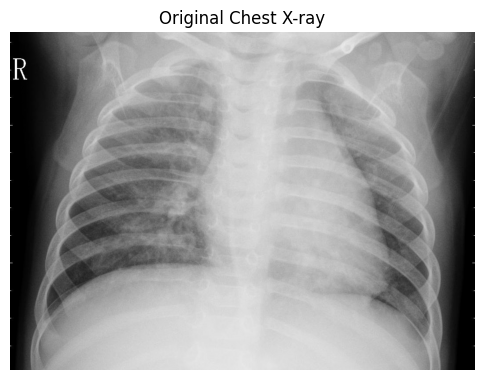

In [ ]:
img = Image.open(sample_path).convert("L")

print("Original size:", img.size)

img_np = np.array(img)

plt.figure(figsize=(6, 6))
plt.imshow(img_np, cmap="gray")
plt.title("Original Chest X-ray")
plt.axis("off");

In [ ]:
import torch
import torchxrayvision as xrv
import torchvision
import numpy as np
import matplotlib.pyplot as plt

# Load image using TorchXRayVision's expected preprocessing
img = xrv.utils.load_image(sample_path)

print("After loading:", img.shape)

# Center crop + resize
transform = torchvision.transforms.Compose([
    xrv.datasets.XRayCenterCrop(),
    xrv.datasets.XRayResizer(512)
])

img_processed = transform(img)

print("After preprocessing:", img_processed.shape)

# Convert to tensor and add batch dimension
img_tensor = torch.from_numpy(img_processed).unsqueeze(0)

print("Model input:", img_tensor.shape)

# Run segmentation
with torch.no_grad():
    output = seg_model(img_tensor)

print("Segmentation output:", output.shape)
print("Targets:")
print(seg_model.targets)

After loading: (1, 768, 1056)
After preprocessing: (1, 512, 512)
Model input: torch.Size([1, 1, 512, 512])
Segmentation output: torch.Size([1, 14, 512, 512])
Targets:
['Left Clavicle', 'Right Clavicle', 'Left Scapula', 'Right Scapula', 'Left Lung', 'Right Lung', 'Left Hilus Pulmonis', 'Right Hilus Pulmonis', 'Heart', 'Aorta', 'Facies Diaphragmatica', 'Mediastinum', 'Weasand', 'Spine']


In [ ]:
# Extract left and right lung masks
left_lung_mask = output[0, 4].cpu().numpy()
right_lung_mask = output[0, 5].cpu().numpy()

# Combine both lungs
lung_mask = np.maximum(left_lung_mask, right_lung_mask)

print("Left lung range:", left_lung_mask.min(), left_lung_mask.max())
print("Right lung range:", right_lung_mask.min(), right_lung_mask.max())
print("Combined mask range:", lung_mask.min(), lung_mask.max())

Left lung range: -9.084903 9.003745
Right lung range: -8.42474 10.815008
Combined mask range: -7.6421623 10.815008


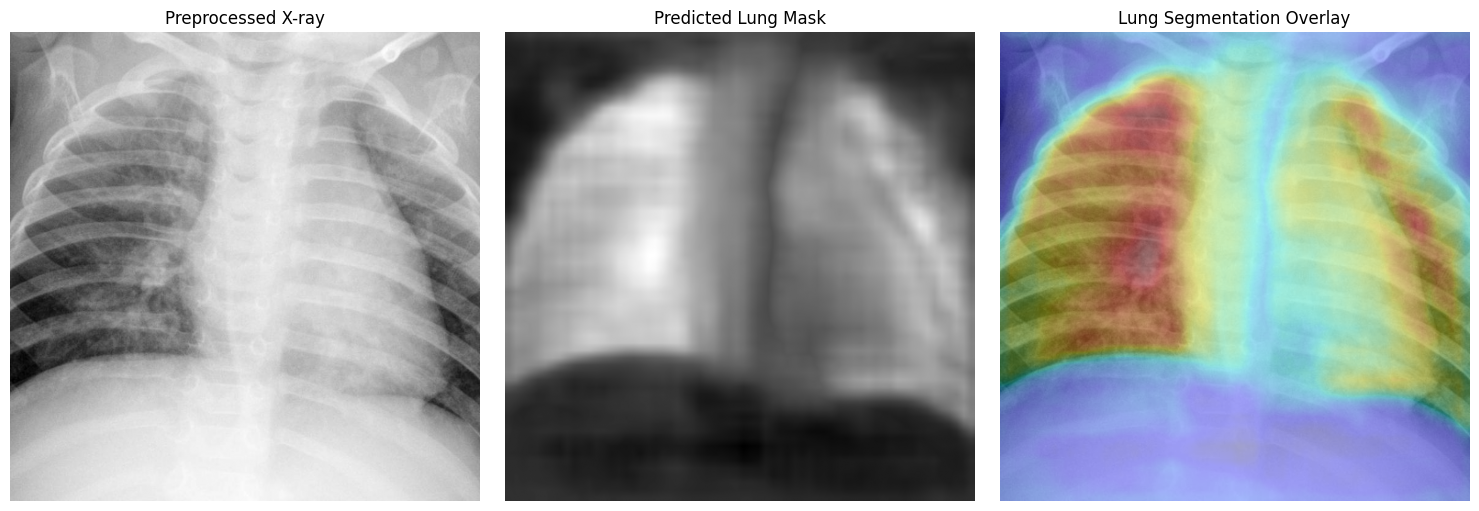

In [ ]:
plt.figure(figsize=(15, 5))

# Original
plt.subplot(1, 3, 1)
plt.imshow(img_processed[0], cmap="gray")
plt.title("Preprocessed X-ray")
plt.axis("off")

# Lung mask
plt.subplot(1, 3, 2)
plt.imshow(lung_mask, cmap="gray")
plt.title("Predicted Lung Mask")
plt.axis("off")

# Overlay
plt.subplot(1, 3, 3)
plt.imshow(img_processed[0], cmap="gray")
plt.imshow(lung_mask, cmap="jet", alpha=0.35)
plt.title("Lung Segmentation Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Convert segmentation logits to probabilities
left_prob = 1 / (1 + np.exp(-left_lung_mask))
right_prob = 1 / (1 + np.exp(-right_lung_mask))

# Combine both lungs
lung_prob = np.maximum(left_prob, right_prob)

# Binary lung mask
lung_binary = (lung_prob > 0.5).astype(np.float32)

print("Probability range:", lung_prob.min(), lung_prob.max())
print("Lung pixels:", lung_binary.sum())
print("Total pixels:", lung_binary.size)
print("Lung coverage:", lung_binary.mean() * 100, "%")

Probability range: 0.00047955976 0.99997985
Lung pixels: 131661.0
Total pixels: 262144
Lung coverage: 50.224686 %


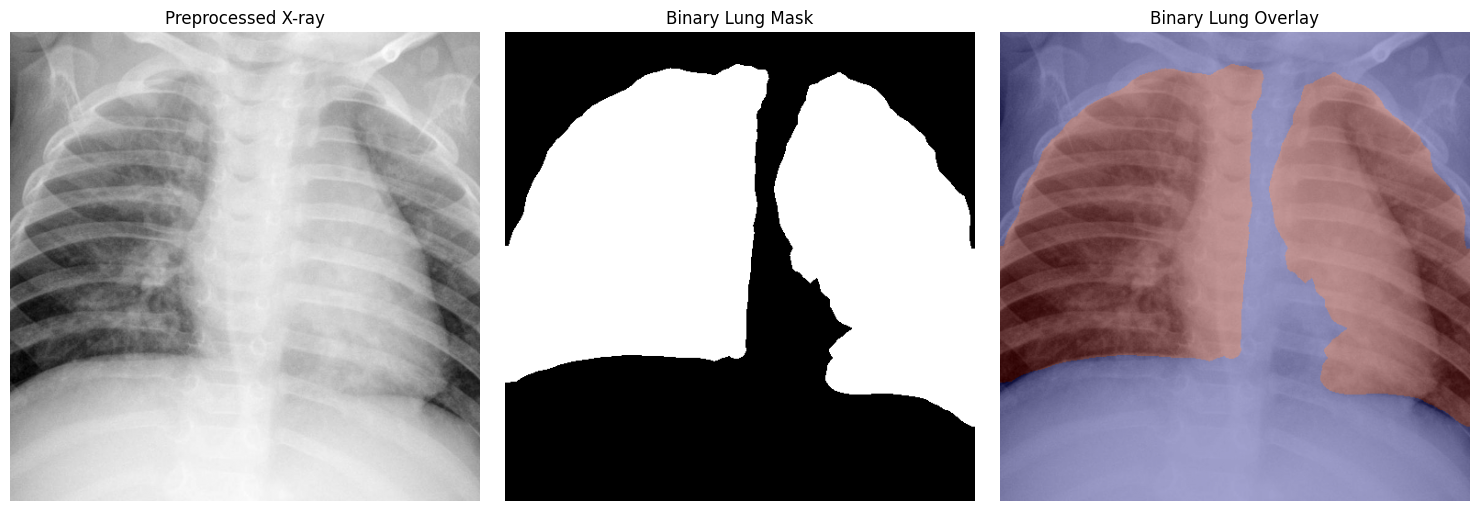

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_processed[0], cmap="gray")
plt.title("Preprocessed X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(lung_binary, cmap="gray")
plt.title("Binary Lung Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_processed[0], cmap="gray")
plt.imshow(lung_binary, cmap="jet", alpha=0.35)
plt.title("Binary Lung Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Create lung-focused X-ray
lung_focused = img_processed[0] * lung_binary

print("Lung-focused shape:", lung_focused.shape)
print("Lung-focused range:", lung_focused.min(), lung_focused.max())

Lung-focused shape: (512, 512)
Lung-focused range: -759.95703 742.89355


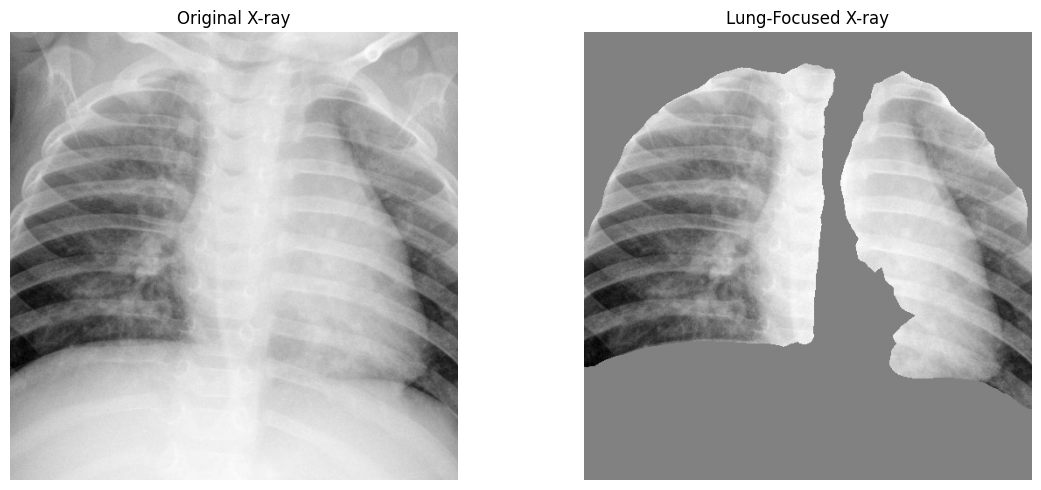

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_processed[0], cmap="gray")
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lung_focused, cmap="gray")
plt.title("Lung-Focused X-ray")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import torch
import torchxrayvision as xrv
import torchvision
from PIL import Image


def create_lung_focused_image(image_path):
    # Load grayscale X-ray
    img = xrv.utils.load_image(image_path)

    # Preprocess for segmentation model
    transform = torchvision.transforms.Compose([
        xrv.datasets.XRayCenterCrop(),
        xrv.datasets.XRayResizer(512)
    ])

    img_processed = transform(img)

    # Convert to tensor
    img_tensor = torch.from_numpy(img_processed).unsqueeze(0)

    # Segmentation inference
    with torch.no_grad():
        segmentation = seg_model(img_tensor)

    # Left Lung = channel 4
    # Right Lung = channel 5
    left_logits = segmentation[0, 4].cpu().numpy()
    right_logits = segmentation[0, 5].cpu().numpy()

    # Convert logits → probabilities
    left_prob = 1 / (1 + np.exp(-left_logits))
    right_prob = 1 / (1 + np.exp(-right_logits))

    # Combine lungs
    lung_prob = np.maximum(left_prob, right_prob)

    # Binary mask
    lung_mask = (lung_prob > 0.5).astype(np.float32)

    # Apply mask
    lung_focused = img_processed[0] * lung_mask

    return lung_focused, lung_mask

In [ ]:
normal_images = glob.glob("/content/Dataset/train/NORMAL/*")
pneumonia_images = glob.glob("/content/Dataset/train/PNEUMONIA/*")

normal_sample = random.choice(normal_images)
pneumonia_sample = random.choice(pneumonia_images)

normal_lung, normal_mask = create_lung_focused_image(normal_sample)
pneumonia_lung, pneumonia_mask = create_lung_focused_image(pneumonia_sample)

print("Normal:", normal_lung.shape)
print("Pneumonia:", pneumonia_lung.shape)

Normal: (512, 512)
Pneumonia: (512, 512)


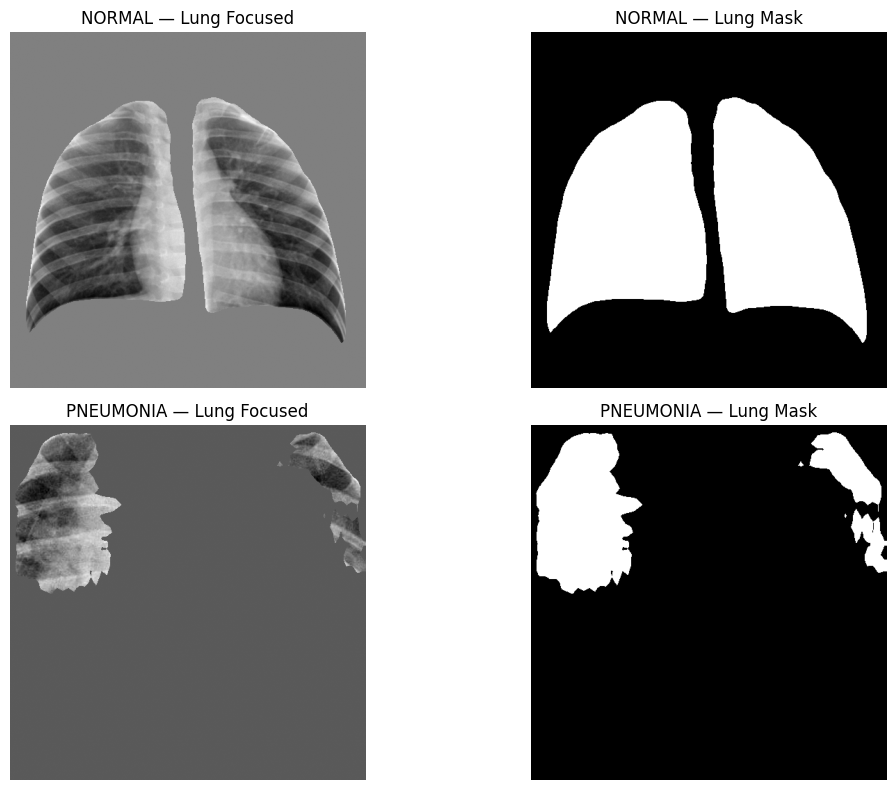

In [ ]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(normal_lung, cmap="gray")
plt.title("NORMAL — Lung Focused")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(normal_mask, cmap="gray")
plt.title("NORMAL — Lung Mask")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(pneumonia_lung, cmap="gray")
plt.title("PNEUMONIA — Lung Focused")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(pneumonia_mask, cmap="gray")
plt.title("PNEUMONIA — Lung Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Get raw segmentation output for the pneumonia sample
img = xrv.utils.load_image(pneumonia_sample)

transform = torchvision.transforms.Compose([
    xrv.datasets.XRayCenterCrop(),
    xrv.datasets.XRayResizer(512)
])

img_processed_p = transform(img)
img_tensor_p = torch.from_numpy(img_processed_p).unsqueeze(0)

with torch.no_grad():
    output_p = seg_model(img_tensor_p)

# Lung channels
left_logits = output_p[0, 4].cpu().numpy()
right_logits = output_p[0, 5].cpu().numpy()

left_prob = 1 / (1 + np.exp(-left_logits))
right_prob = 1 / (1 + np.exp(-right_logits))

lung_prob_p = np.maximum(left_prob, right_prob)

print("Probability range:",
      lung_prob_p.min(),
      lung_prob_p.max())

Probability range: 0.0007475954 0.94576776


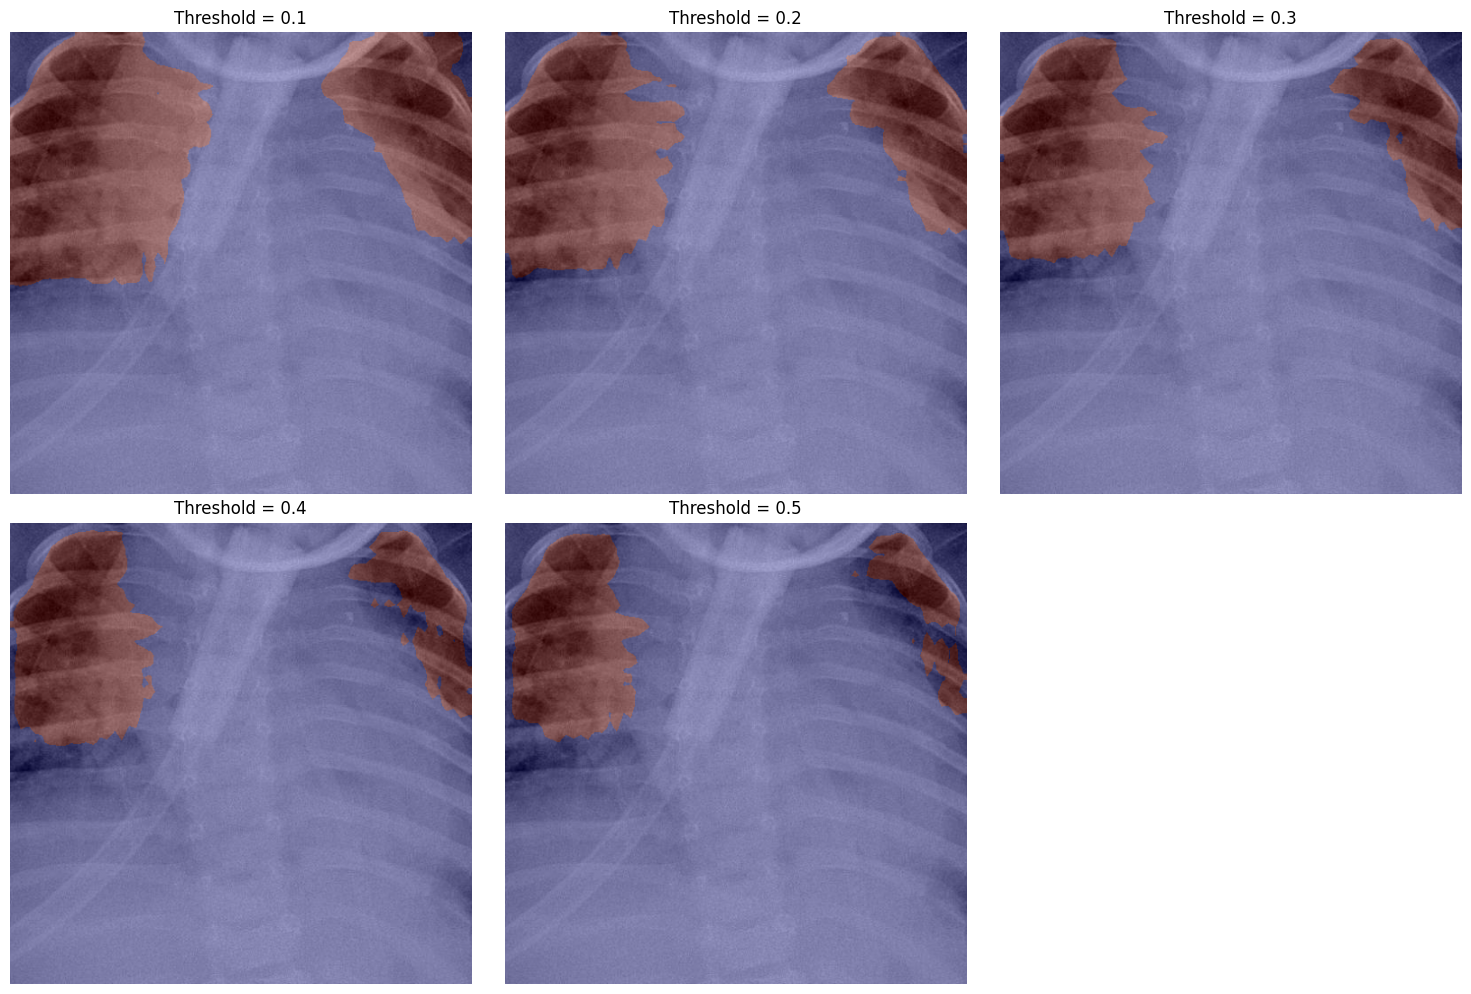

In [ ]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

plt.figure(figsize=(15, 10))

for i, threshold in enumerate(thresholds):

    mask = (lung_prob_p > threshold).astype(np.float32)

    plt.subplot(2, 3, i + 1)
    plt.imshow(img_processed_p[0], cmap="gray")
    plt.imshow(mask, cmap="jet", alpha=0.35)
    plt.title(f"Threshold = {threshold}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Find the last convolutional layer in DenseNet121
for layer in reversed(densenet_model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        print("Last Conv2D layer:", layer.name)
        break

In [ ]:
base_model = densenet_model.layers[0]

for layer in reversed(base_model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        print("Last Conv2D layer:", layer.name)
        break

Last Conv2D layer: conv5_block16_2_conv


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    # DenseNet backbone
    base_model = model.layers[0]

    # Make sure the backbone is built
    _ = base_model(img_array, training=False)

    # Target convolutional layer
    last_conv_layer = base_model.get_layer(last_conv_layer_name)

    # Create a connected model:
    # input → DenseNet → conv output + backbone output
    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:

        # Both outputs come from the SAME forward graph
        conv_outputs, backbone_output = grad_model(
            img_array,
            training=False
        )

        # Pass backbone output through your trained classification head
        x = model.layers[1](backbone_output, training=False)
        x = model.layers[2](x, training=False)
        x = model.layers[3](x, training=False)
        predictions = model.layers[4](x, training=False)

        # Pneumonia probability
        pneumonia_score = predictions[:, 0]

    # Gradient of pneumonia prediction
    # with respect to convolutional feature maps
    grads = tape.gradient(
        pneumonia_score,
        conv_outputs
    )

    if grads is None:
        raise RuntimeError(
            "Gradients are None. The prediction is not connected "
            "to the selected convolutional layer."
        )

    # Global average pooling of gradients
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # Remove batch dimension
    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # Keep only positive influence
    heatmap = tf.maximum(heatmap, 0)

    # Normalize to 0–1
    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy()

In [ ]:
import glob
import random

test_normal = glob.glob("/content/Dataset/test/NORMAL/*")
test_pneumonia = glob.glob("/content/Dataset/test/PNEUMONIA/*")

sample_test_normal = random.choice(test_normal)
sample_test_pneumonia = random.choice(test_pneumonia)

print("NORMAL:", sample_test_normal)
print("PNEUMONIA:", sample_test_pneumonia)

NORMAL: /content/Dataset/test/NORMAL/NORMAL2-IM-0028-0001.jpeg
PNEUMONIA: /content/Dataset/test/PNEUMONIA/person21_virus_53.jpeg


In [ ]:
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.densenet import preprocess_input

img_path = sample_test_pneumonia

img = image.load_img(
    img_path,
    target_size=(224, 224),
    color_mode="rgb"
)

img_array = image.img_to_array(img)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# DenseNet preprocessing
img_array = preprocess_input(img_array)

print("Input shape:", img_array.shape)

Input shape: (1, 224, 224, 3)


In [ ]:
# Explicitly call the trained model once
test_prediction = densenet_model(img_array)

print("Prediction:", float(test_prediction[0][0]))
print("Model input:", densenet_model.input_shape)
print("Model output:", densenet_model.output_shape)

Prediction: 0.8696973323822021
Model input: (None, 224, 224, 3)
Model output: (None, 1)


In [ ]:
heatmap = make_gradcam_heatmap(
    img_array,
    densenet_model,
    "conv5_block16_2_conv"
)

print("Heatmap shape:", heatmap.shape)
print("Heatmap range:", heatmap.min(), heatmap.max())

Heatmap shape: (7, 7)
Heatmap range: 0.0 1.0


In [ ]:
import cv2

# Resize 7x7 Grad-CAM → 224x224
heatmap_resized = cv2.resize(
    heatmap,
    (224, 224)
)

# Load original image for visualization
original_img = image.load_img(
    img_path,
    target_size=(224, 224),
    color_mode="rgb"
)

original_img = image.img_to_array(original_img).astype(np.uint8)

# Convert heatmap to RGB
heatmap_uint8 = np.uint8(255 * heatmap_resized)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

# OpenCV uses BGR → convert to RGB
heatmap_color = cv2.cvtColor(
    heatmap_color,
    cv2.COLOR_BGR2RGB
)

# Overlay
overlay = cv2.addWeighted(
    original_img,
    0.6,
    heatmap_color,
    0.4,
    0
)

# Get prediction
prediction = float(densenet_model.predict(img_array, verbose=0)[0][0])

print(f"Pneumonia probability: {prediction:.4f}")
print(f"Pneumonia probability: {prediction * 100:.2f}%")

Pneumonia probability: 0.8697
Pneumonia probability: 86.97%


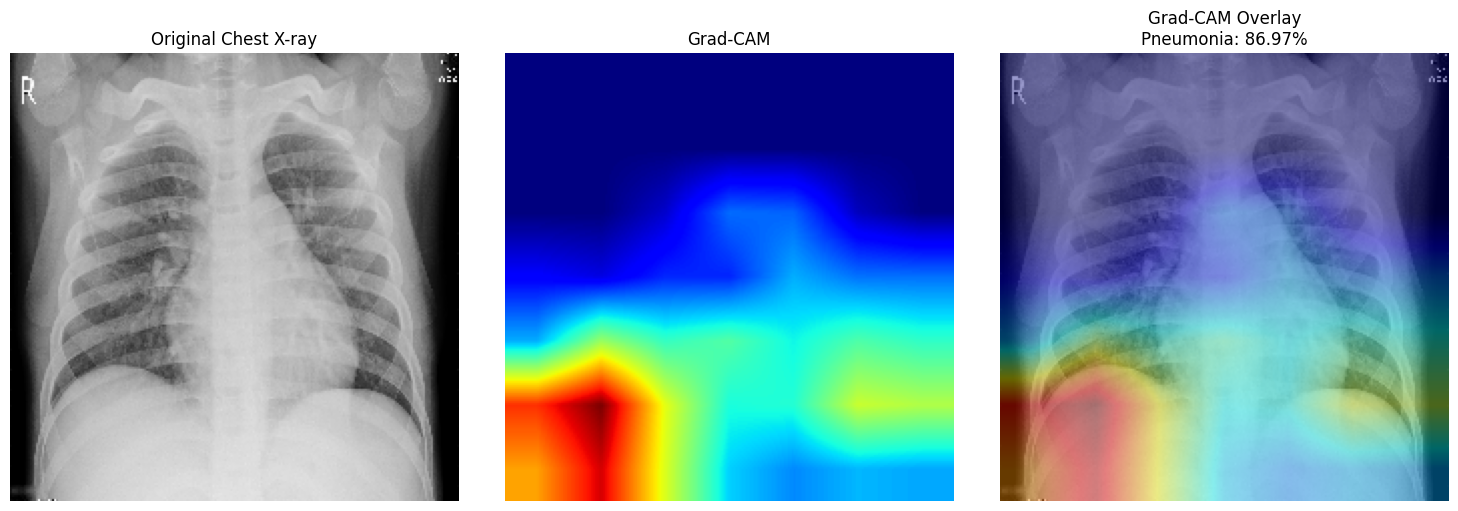

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_img)
plt.title("Original Chest X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(f"Grad-CAM Overlay\nPneumonia: {prediction:.2%}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Generate lung segmentation for the SAME image used for Grad-CAM

seg_img = xrv.utils.load_image(img_path)

seg_transform = torchvision.transforms.Compose([
    xrv.datasets.XRayCenterCrop(),
    xrv.datasets.XRayResizer(512)
])

seg_img_processed = seg_transform(seg_img)

seg_tensor = torch.from_numpy(
    seg_img_processed
).unsqueeze(0)

with torch.no_grad():
    seg_output = seg_model(seg_tensor)

# Left and right lung channels
left_logits = seg_output[0, 4].cpu().numpy()
right_logits = seg_output[0, 5].cpu().numpy()

# Convert logits to probabilities
left_prob = 1 / (1 + np.exp(-left_logits))
right_prob = 1 / (1 + np.exp(-right_logits))

# Combine lungs
same_image_lung_prob = np.maximum(
    left_prob,
    right_prob
)

# Binary mask
same_image_lung_mask = (
    same_image_lung_prob > 0.5
).astype(np.float32)

print("Segmentation image:", img_path)
print("Mask shape:", same_image_lung_mask.shape)
print("Lung coverage:",
      same_image_lung_mask.mean() * 100, "%")

Segmentation image: /content/Dataset/test/PNEUMONIA/person21_virus_53.jpeg
Mask shape: (512, 512)
Lung coverage: 48.588562 %


In [ ]:
# Resize lung mask from 512x512 → 224x224
lung_mask_224 = cv2.resize(
    same_image_lung_mask,
    (224, 224),
    interpolation=cv2.INTER_NEAREST
)

print("Grad-CAM:", heatmap_resized.shape)
print("Lung mask:", lung_mask_224.shape)

Grad-CAM: (224, 224)
Lung mask: (224, 224)


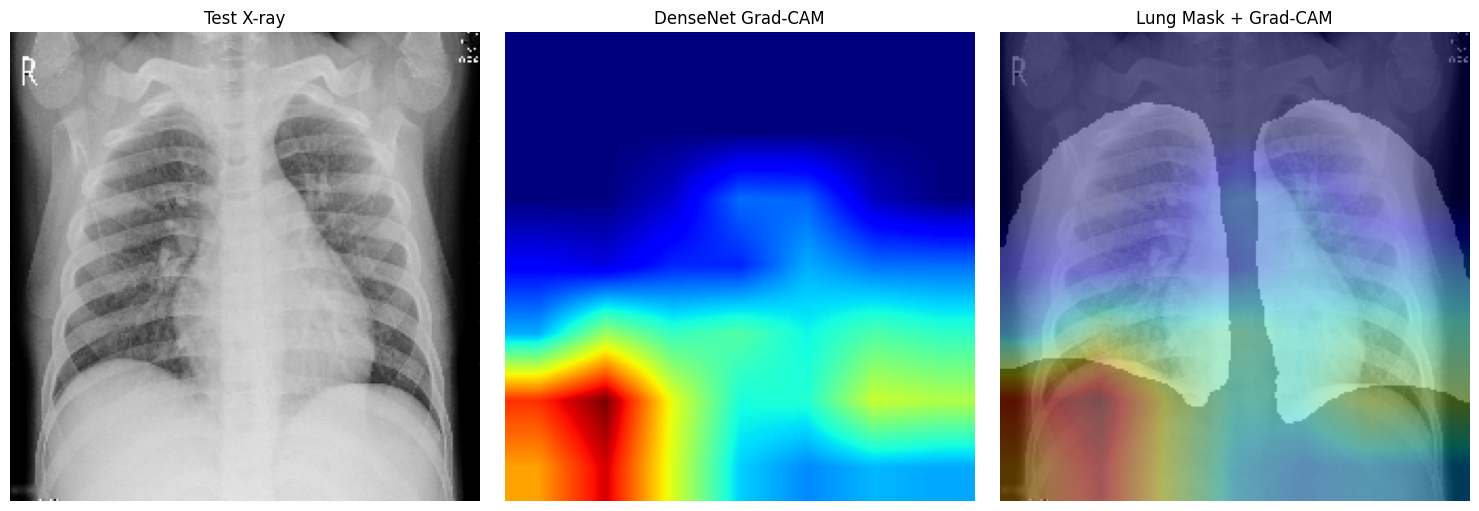

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_img)
plt.title("Test X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("DenseNet Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(original_img)
plt.imshow(
    lung_mask_224,
    cmap="gray",
    alpha=0.35
)
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.35
)
plt.title("Lung Mask + Grad-CAM")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Ensure both arrays are float
cam = heatmap_resized.astype(np.float32)
mask = lung_mask_224.astype(np.float32)

# Total Grad-CAM activation
total_attention = cam.sum()

# Grad-CAM activation inside lungs
lung_attention = (cam * mask).sum()

# Percentage of attention inside lungs
attention_inside_lung = (
    lung_attention / total_attention
) * 100

print(f"Total Grad-CAM activation: {total_attention:.4f}")
print(f"Activation inside lungs: {lung_attention:.4f}")
print(f"Attention inside lungs: {attention_inside_lung:.2f}%")

Total Grad-CAM activation: 12938.5820
Activation inside lungs: 5412.7104
Attention inside lungs: 41.83%


In [ ]:
# Top 20% Grad-CAM activation threshold
cam_threshold = np.percentile(cam, 80)

high_attention = cam >= cam_threshold

# Number of high-attention pixels
total_high_attention = high_attention.sum()

# High-attention pixels inside lung
high_attention_inside = (
    high_attention & (mask > 0)
).sum()

# Percentage of high-attention pixels inside lungs
high_attention_lung_percentage = (
    high_attention_inside / total_high_attention
) * 100

print(f"Grad-CAM threshold (80th percentile): {cam_threshold:.4f}")
print(f"High-attention pixels: {total_high_attention}")
print(f"High-attention pixels inside lungs: {high_attention_inside}")
print(
    f"High-attention region inside lungs: "
    f"{high_attention_lung_percentage:.2f}%"
)

Grad-CAM threshold (80th percentile): 0.4552
High-attention pixels: 10036
High-attention pixels inside lungs: 2812
High-attention region inside lungs: 28.02%


In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import cv2
import torch
import torchvision
import tensorflow as tf

# --------------------------------------------------
# Select a reproducible 20-image pilot set
# --------------------------------------------------

normal_test_images = sorted(
    glob.glob("/content/Dataset/test/NORMAL/*")
)

pneumonia_test_images = sorted(
    glob.glob("/content/Dataset/test/PNEUMONIA/*")
)

pilot_normal = normal_test_images[:10]
pilot_pneumonia = pneumonia_test_images[:10]

pilot_images = (
    [(p, 0) for p in pilot_normal] +
    [(p, 1) for p in pilot_pneumonia]
)

print("Pilot images:", len(pilot_images))
print("NORMAL:", len(pilot_normal))
print("PNEUMONIA:", len(pilot_pneumonia))

Pilot images: 20
NORMAL: 10
PNEUMONIA: 10


In [ ]:
def calculate_attention_overlap(image_path):

    # ==================================================
    # 1. DenseNet preprocessing
    # ==================================================

    img = image.load_img(
        image_path,
        target_size=(224, 224),
        color_mode="rgb"
    )

    original = image.img_to_array(img).astype(np.uint8)

    img_array = np.expand_dims(
        original.astype(np.float32),
        axis=0
    )

    img_array = preprocess_input(img_array)

    # ==================================================
    # 2. DenseNet prediction
    # ==================================================

    prediction = float(
        densenet_model.predict(
            img_array,
            verbose=0
        )[0][0]
    )

    # ==================================================
    # 3. Grad-CAM
    # ==================================================

    heatmap = make_gradcam_heatmap(
        img_array,
        densenet_model,
        "conv5_block16_2_conv"
    )

    heatmap_224 = cv2.resize(
        heatmap,
        (224, 224),
        interpolation=cv2.INTER_LINEAR
    )

    # ==================================================
    # 4. PSPNet lung segmentation
    # ==================================================

    seg_img = xrv.utils.load_image(image_path)

    seg_transform = torchvision.transforms.Compose([
        xrv.datasets.XRayCenterCrop(),
        xrv.datasets.XRayResizer(512)
    ])

    seg_processed = seg_transform(seg_img)

    seg_tensor = torch.from_numpy(
        seg_processed
    ).unsqueeze(0)

    # Use same device as segmentation model
    try:
        seg_device = next(seg_model.parameters()).device
        seg_tensor = seg_tensor.to(seg_device)
    except StopIteration:
        pass

    with torch.no_grad():
        seg_output = seg_model(seg_tensor)

    # Left Lung = 4
    # Right Lung = 5
    left_logits = seg_output[0, 4].detach().cpu().numpy()
    right_logits = seg_output[0, 5].detach().cpu().numpy()

    left_prob = 1 / (1 + np.exp(-left_logits))
    right_prob = 1 / (1 + np.exp(-right_logits))

    lung_prob = np.maximum(
        left_prob,
        right_prob
    )

    lung_mask = (
        lung_prob > 0.5
    ).astype(np.float32)

    # Resize 512 → 224
    lung_mask_224 = cv2.resize(
        lung_mask,
        (224, 224),
        interpolation=cv2.INTER_NEAREST
    )

    # ==================================================
    # 5. Attention inside lung
    # ==================================================

    total_attention = heatmap_224.sum()

    lung_attention = (
        heatmap_224 * lung_mask_224
    ).sum()

    attention_inside_lung = (
        lung_attention / total_attention * 100
        if total_attention > 0
        else np.nan
    )

    # ==================================================
    # 6. Top 20% Grad-CAM region
    # ==================================================

    cam_threshold = np.percentile(
        heatmap_224,
        80
    )

    high_attention = (
        heatmap_224 >= cam_threshold
    )

    total_high_attention = (
        high_attention.sum()
    )

    high_attention_inside = (
        high_attention &
        (lung_mask_224 > 0)
    ).sum()

    high_attention_lung_percentage = (
        high_attention_inside /
        total_high_attention * 100
        if total_high_attention > 0
        else np.nan
    )

    return {
        "image": os.path.basename(image_path),
        "prediction": prediction,
        "attention_inside_lung_pct":
            attention_inside_lung,
        "high_attention_inside_lung_pct":
            high_attention_lung_percentage,
        "lung_coverage_pct":
            lung_mask_224.mean() * 100
    }

In [ ]:
results = []

for i, (path, true_label) in enumerate(pilot_images):

    print(
        f"[{i+1}/{len(pilot_images)}] "
        f"{os.path.basename(path)}"
    )

    result = calculate_attention_overlap(path)

    result["true_label"] = true_label

    results.append(result)

pilot_results = pd.DataFrame(results)

pilot_results

[1/20] IM-0001-0001.jpeg
[2/20] IM-0003-0001.jpeg
[3/20] IM-0005-0001.jpeg
[4/20] IM-0006-0001.jpeg
[5/20] IM-0007-0001.jpeg
[6/20] IM-0009-0001.jpeg
[7/20] IM-0010-0001.jpeg
[8/20] IM-0011-0001-0001.jpeg
[9/20] IM-0011-0001-0002.jpeg
[10/20] IM-0011-0001.jpeg
[11/20] person100_bacteria_475.jpeg
[12/20] person100_bacteria_477.jpeg
[13/20] person100_bacteria_478.jpeg
[14/20] person100_bacteria_479.jpeg
[15/20] person100_bacteria_480.jpeg
[16/20] person100_bacteria_481.jpeg
[17/20] person100_bacteria_482.jpeg
[18/20] person101_bacteria_483.jpeg
[19/20] person101_bacteria_484.jpeg
[20/20] person101_bacteria_485.jpeg


,image,prediction,attention_inside_lung_pct,high_attention_inside_lung_pct,lung_coverage_pct,true_label
0,IM-0001-0001.jpeg,0.106052,87.063126,90.456762,62.607620,0
1,IM-0003-0001.jpeg,0.069329,77.461258,78.945795,57.942043,0
2,IM-0005-0001.jpeg,0.069488,59.789371,61.289358,52.684551,0
3,IM-0006-0001.jpeg,0.156070,64.102226,69.689119,60.883690,0
4,IM-0007-0001.jpeg,0.073139,56.781155,58.752615,54.033806,0
5,IM-0009-0001.jpeg,0.004964,64.665329,57.323635,52.379627,0
6,IM-0010-0001.jpeg,0.006202,66.626015,67.028697,49.762836,0
7,IM-0011-0001-0001.jpeg,0.127473,41.919731,35.651654,49.689095,0
8,IM-0011-0001-0002.jpeg,0.561506,55.925549,67.875648,50.508213,0
9,IM-0011-0001.jpeg,0.021464,71.396927,70.286967,43.933357,0


In [ ]:
# ============================================================
# FULL TEST-SET GRAD-CAM + LUNG OVERLAP ANALYSIS
# ============================================================

all_test_images = (
    [(p, 0) for p in normal_test_images] +
    [(p, 1) for p in pneumonia_test_images]
)

print("Total test images:", len(all_test_images))
print("NORMAL:", len(normal_test_images))
print("PNEUMONIA:", len(pneumonia_test_images))

Total test images: 640
NORMAL: 234
PNEUMONIA: 406


In [10]:
model_path = "/content/drive/MyDrive/AI_Pneumonia_Detection/models/densenet121_final.keras"

densenet_model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("DenseNet loaded successfully.")
print("Input shape:", densenet_model.input_shape)

DenseNet loaded successfully.
Input shape: (None, 224, 224, 3)


In [11]:
seg_model = xrv.baseline_models.chestx_det.PSPNet()
seg_model.eval()

print("Segmentation model loaded.")

If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/pspnet_chestxray_best_model_4.pth -O /root/.torchxrayvision/models_data/pspnet_chestxray_best_model_4.pth`
[██████████████████████████████████████████████████]
Segmentation model loaded.


In [12]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):

    base_model = model.layers[0]

    _ = base_model(img_array, training=False)

    last_conv_layer = base_model.get_layer(
        last_conv_layer_name
    )

    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, backbone_output = grad_model(
            img_array,
            training=False
        )

        x = model.layers[1](backbone_output, training=False)
        x = model.layers[2](x, training=False)
        x = model.layers[3](x, training=False)
        predictions = model.layers[4](x, training=False)

        pneumonia_score = predictions[:, 0]

    grads = tape.gradient(
        pneumonia_score,
        conv_outputs
    )

    if grads is None:
        raise RuntimeError("Gradients are None.")

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy()

In [13]:
last_conv_layer_name = "conv5_block16_2_conv"

print("Grad-CAM layer:", last_conv_layer_name)

Grad-CAM layer: conv5_block16_2_conv


In [14]:
def calculate_attention_overlap(image_path):

    # -----------------------------
    # 1. Load and preprocess image
    # -----------------------------
    img = image.load_img(
        image_path,
        target_size=(224, 224),
        color_mode="rgb"
    )

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    img_array = preprocess_input(img_array)

    # -----------------------------
    # 2. DenseNet prediction
    # -----------------------------
    prediction = float(
        densenet_model.predict(
            img_array,
            verbose=0
        )[0][0]
    )

    # -----------------------------
    # 3. Grad-CAM
    # -----------------------------
    cam = make_gradcam_heatmap(
        img_array,
        densenet_model,
        last_conv_layer_name
    )

    cam = cv2.resize(
        cam,
        (224, 224)
    )

    # -----------------------------
    # 4. PSPNet lung segmentation
    # -----------------------------
    xray = xrv.utils.load_image(image_path)

    transform = torchvision.transforms.Compose([
        xrv.datasets.XRayCenterCrop(),
        xrv.datasets.XRayResizer(512)
    ])

    xray_processed = transform(xray)

    xray_tensor = torch.from_numpy(
        xray_processed
    ).unsqueeze(0)

    with torch.no_grad():
        output = seg_model(xray_tensor)

    output = output.detach().cpu().numpy()[0]

    # Left Lung = channel 4
    # Right Lung = channel 5

    left_logits = output[4]
    right_logits = output[5]

    left_prob = 1 / (1 + np.exp(-left_logits))
    right_prob = 1 / (1 + np.exp(-right_logits))

    lung_prob = np.maximum(
        left_prob,
        right_prob
    )

    lung_binary = (
        lung_prob > 0.5
    ).astype(np.float32)

    lung_mask = cv2.resize(
        lung_binary,
        (224, 224),
        interpolation=cv2.INTER_NEAREST
    )

    # -----------------------------
    # 5. Attention inside lung
    # -----------------------------
    total_attention = cam.sum()

    lung_attention = (
        cam * lung_mask
    ).sum()

    if total_attention > 0:
        attention_inside_lung = (
            lung_attention /
            total_attention
        ) * 100
    else:
        attention_inside_lung = 0

    # -----------------------------
    # 6. High-attention region
    # -----------------------------
    cam_threshold = np.percentile(
        cam,
        80
    )

    high_attention = (
        cam >= cam_threshold
    )

    high_attention_inside = (
        high_attention &
        (lung_mask > 0)
    ).sum()

    total_high_attention = (
        high_attention.sum()
    )

    if total_high_attention > 0:
        high_attention_lung_percentage = (
            high_attention_inside /
            total_high_attention
        ) * 100
    else:
        high_attention_lung_percentage = 0

    # -----------------------------
    # 7. Lung coverage
    # -----------------------------
    lung_coverage = (
        lung_mask.sum() /
        lung_mask.size
    ) * 100

    return {
        "image": os.path.basename(image_path),
        "prediction": prediction,
        "attention_inside_lung_pct": attention_inside_lung,
        "high_attention_inside_lung_pct":
            high_attention_lung_percentage,
        "lung_coverage_pct": lung_coverage
    }

In [15]:
normal_test_images = sorted(
    glob.glob("/content/Dataset/test/NORMAL/*")
)

pneumonia_test_images = sorted(
    glob.glob("/content/Dataset/test/PNEUMONIA/*")
)

all_test_images = (
    [(p, 0) for p in normal_test_images] +
    [(p, 1) for p in pneumonia_test_images]
)

print("NORMAL:", len(normal_test_images))
print("PNEUMONIA:", len(pneumonia_test_images))
print("TOTAL:", len(all_test_images))

NORMAL: 234
PNEUMONIA: 406
TOTAL: 640


In [16]:
test_path, test_label = all_test_images[0]

result = calculate_attention_overlap(test_path)

print(result)

{'image': 'IM-0001-0001.jpeg', 'prediction': 0.10605223476886749, 'attention_inside_lung_pct': np.float32(87.063126), 'high_attention_inside_lung_pct': np.float64(90.45676186685242), 'lung_coverage_pct': np.float32(62.60762)}


In [17]:
checkpoint_path = (
    "/content/drive/MyDrive/AI_Pneumonia_Detection/"
    "models/densenet_gradcam_lung_overlap_checkpoint.csv"
)

full_results = []

for i, (path, true_label) in enumerate(all_test_images):

    try:

        result = calculate_attention_overlap(path)

        result["true_label"] = true_label

        result["predicted_label"] = (
            1 if result["prediction"] >= 0.10 else 0
        )

        full_results.append(result)

    except Exception as e:

        print(
            f"ERROR: {os.path.basename(path)} → {e}"
        )

    # Save checkpoint every 25 images
    if (i + 1) % 25 == 0:

        checkpoint_df = pd.DataFrame(
            full_results
        )

        checkpoint_df.to_csv(
            checkpoint_path,
            index=False
        )

        print(
            f"Processed {i + 1}/{len(all_test_images)} "
            f"→ checkpoint saved"
        )

print(
    f"\nCompleted: "
    f"{len(full_results)}/{len(all_test_images)}"
)

# Final save
final_df = pd.DataFrame(full_results)

final_path = (
    "/content/drive/MyDrive/AI_Pneumonia_Detection/"
    "models/densenet_gradcam_lung_overlap_full.csv"
)

final_df.to_csv(
    final_path,
    index=False
)

print("\nFinal results saved:")
print(final_path)

Processed 25/640 → checkpoint saved
Processed 50/640 → checkpoint saved
Processed 75/640 → checkpoint saved
Processed 100/640 → checkpoint saved
Processed 125/640 → checkpoint saved
Processed 150/640 → checkpoint saved
Processed 175/640 → checkpoint saved
Processed 200/640 → checkpoint saved
Processed 225/640 → checkpoint saved
Processed 250/640 → checkpoint saved
Processed 275/640 → checkpoint saved
Processed 300/640 → checkpoint saved
Processed 325/640 → checkpoint saved
Processed 350/640 → checkpoint saved
Processed 375/640 → checkpoint saved
Processed 400/640 → checkpoint saved
Processed 425/640 → checkpoint saved
Processed 450/640 → checkpoint saved
Processed 475/640 → checkpoint saved
Processed 500/640 → checkpoint saved
Processed 525/640 → checkpoint saved
Processed 550/640 → checkpoint saved
Processed 575/640 → checkpoint saved
Processed 600/640 → checkpoint saved
Processed 625/640 → checkpoint saved

Completed: 640/640

Final results saved:
/content/drive/MyDrive/AI_Pneumonia_

In [8]:
results_path = (
    "/content/drive/MyDrive/AI_Pneumonia_Detection/"
    "models/densenet_gradcam_lung_overlap_full.csv"
)

results_df = pd.read_csv(results_path)

print("Shape:", results_df.shape)
print("\nColumns:")
print(results_df.columns.tolist())

print("\nFirst 5 rows:")
display(results_df.head())

Shape: (640, 7)

Columns:
['image', 'prediction', 'attention_inside_lung_pct', 'high_attention_inside_lung_pct', 'lung_coverage_pct', 'true_label', 'predicted_label']

First 5 rows:


,image,prediction,attention_inside_lung_pct,high_attention_inside_lung_pct,lung_coverage_pct,true_label,predicted_label
0,IM-0001-0001.jpeg,0.106052,87.063126,90.456762,62.607620,0,1
1,IM-0003-0001.jpeg,0.069329,77.461258,78.945795,57.942043,0,0
2,IM-0005-0001.jpeg,0.069488,59.789371,61.289358,52.684550,0,0
3,IM-0006-0001.jpeg,0.156070,64.102226,69.689119,60.883690,0,1
4,IM-0007-0001.jpeg,0.073139,56.781155,58.752615,54.033806,0,0


In [9]:
print("Rows:", len(results_df))
print("Missing values:")
print(results_df.isnull().sum())

print("\nTrue-label distribution:")
print(results_df["true_label"].value_counts())

print("\nPredicted-label distribution:")
print(results_df["predicted_label"].value_counts())

Rows: 640
Missing values:
image                             0
prediction                        0
attention_inside_lung_pct         0
high_attention_inside_lung_pct    0
lung_coverage_pct                 0
true_label                        0
predicted_label                   0
dtype: int64

True-label distribution:
true_label
1    406
0    234
Name: count, dtype: int64

Predicted-label distribution:
predicted_label
1    517
0    123
Name: count, dtype: int64


In [10]:
results_df[
    [
        "prediction",
        "true_label",
        "predicted_label",
        "attention_inside_lung_pct",
        "high_attention_inside_lung_pct",
        "lung_coverage_pct"
    ]
].describe()

,prediction,true_label,predicted_label,attention_inside_lung_pct,high_attention_inside_lung_pct,lung_coverage_pct
count,640.000000,640.000000,640.000000,640.000000,640.000000,640.000000
mean,0.656701,0.634375,0.807813,46.894282,45.499856,44.144434
std,0.399881,0.481982,0.394328,17.057868,20.341064,12.718470
min,0.000399,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.187089,0.000000,1.000000,36.297868,32.120275,36.873704
50%,0.925531,1.000000,1.000000,46.703581,44.878438,46.794282
75%,0.994644,1.000000,1.000000,57.163883,59.771366,53.238601
max,0.999970,1.000000,1.000000,99.997223,94.928258,68.110250


In [11]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_true = results_df["true_label"]
y_pred = results_df["predicted_label"]
y_prob = results_df["prediction"]

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred
).ravel()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
sensitivity = recall_score(y_true, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_true, y_pred)
auc = roc_auc_score(y_true, y_prob)

print("CONFUSION MATRIX")
print("----------------")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print("\nCLASSIFICATION METRICS")
print("----------------------")
print(f"Accuracy:    {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision:   {precision:.4f} ({precision*100:.2f}%)")
print(f"Sensitivity: {sensitivity:.4f} ({sensitivity*100:.2f}%)")
print(f"Specificity: {specificity:.4f} ({specificity*100:.2f}%)")
print(f"F1 Score:    {f1:.4f} ({f1*100:.2f}%)")
print(f"ROC-AUC:     {auc:.4f}")

CONFUSION MATRIX
----------------
TN: 118
FP: 116
FN: 5
TP: 401

CLASSIFICATION METRICS
----------------------
Accuracy:    0.8109 (81.09%)
Precision:   0.7756 (77.56%)
Sensitivity: 0.9877 (98.77%)
Specificity: 0.5043 (50.43%)
F1 Score:    0.8689 (86.89%)
ROC-AUC:     0.9629


In [12]:
class_summary = (
    results_df
    .groupby("true_label")[
        [
            "prediction",
            "attention_inside_lung_pct",
            "high_attention_inside_lung_pct",
            "lung_coverage_pct"
        ]
    ]
    .agg(["mean", "median", "std"])
)

class_summary

prediction                     attention_inside_lung_pct  \
                 mean    median       std                      mean   
true_label                                                            
0            0.215375  0.091886  0.263051                 56.095589   
1            0.911062  0.988210  0.187332                 41.591065   

                                 high_attention_inside_lung_pct             \
               median        std                           mean     median   
true_label                                                                   
0           56.574917  17.012211                      54.660341  53.409000   
1           43.077736  14.679021                      40.220167  39.931248   

                      lung_coverage_pct                        
                  std              mean     median        std  
true_label                                                     
0           18.755565         49.500093  50.204279   8.587011  
1           19.339460         41.057674  43.663305  13.662908

In [13]:
from scipy.stats import mannwhitneyu

normal = results_df[
    results_df["true_label"] == 0
]

pneumonia = results_df[
    results_df["true_label"] == 1
]

metrics = [
    "attention_inside_lung_pct",
    "high_attention_inside_lung_pct",
    "lung_coverage_pct"
]

for metric in metrics:

    stat, p_value = mannwhitneyu(
        normal[metric],
        pneumonia[metric],
        alternative="two-sided"
    )

    print(f"\n{metric}")
    print("-" * len(metric))
    print(f"Normal median:    {normal[metric].median():.3f}")
    print(f"Pneumonia median: {pneumonia[metric].median():.3f}")
    print(f"U statistic:      {stat:.2f}")
    print(f"p-value:          {p_value:.6e}")


attention_inside_lung_pct
-------------------------
Normal median:    56.575
Pneumonia median: 43.078
U statistic:      70777.50
p-value:          5.054583e-25

high_attention_inside_lung_pct
------------------------------
Normal median:    53.409
Pneumonia median: 39.931
U statistic:      66910.00
p-value:          6.987565e-18

lung_coverage_pct
-----------------
Normal median:    50.204
Pneumonia median: 43.663
U statistic:      65145.50
p-value:          4.808198e-15


In [14]:
results_df["correct"] = (
    results_df["true_label"] ==
    results_df["predicted_label"]
)

print(
    results_df["correct"]
    .value_counts()
    .rename({
        True: "Correct",
        False: "Incorrect"
    })
)

correct = results_df[
    results_df["correct"] == True
]

incorrect = results_df[
    results_df["correct"] == False
]

metrics = [
    "attention_inside_lung_pct",
    "high_attention_inside_lung_pct",
    "lung_coverage_pct"
]

for metric in metrics:

    print(f"\n{metric}")
    print("-" * len(metric))

    print(
        f"Correct:   "
        f"mean={correct[metric].mean():.3f}, "
        f"median={correct[metric].median():.3f}"
    )

    print(
        f"Incorrect: "
        f"mean={incorrect[metric].mean():.3f}, "
        f"median={incorrect[metric].median():.3f}"
    )

correct
Correct      519
Incorrect    121
Name: count, dtype: int64

attention_inside_lung_pct
-------------------------
Correct:   mean=45.608, median=45.155
Incorrect: mean=52.411, median=53.585

high_attention_inside_lung_pct
------------------------------
Correct:   mean=44.433, median=43.005
Incorrect: mean=50.076, median=48.645

lung_coverage_pct
-----------------
Correct:   mean=42.764, median=45.358
Incorrect: mean=50.064, median=50.508


In [15]:
from scipy.stats import mannwhitneyu

for metric in [
    "attention_inside_lung_pct",
    "high_attention_inside_lung_pct",
    "lung_coverage_pct"
]:

    stat, p_value = mannwhitneyu(
        correct[metric],
        incorrect[metric],
        alternative="two-sided"
    )

    print(f"\n{metric}")
    print("-" * len(metric))
    print(f"U statistic: {stat:.2f}")
    print(f"p-value:    {p_value:.6e}")


attention_inside_lung_pct
-------------------------
U statistic: 23234.00
p-value:    8.272203e-06

high_attention_inside_lung_pct
------------------------------
U statistic: 26081.00
p-value:    3.689207e-03

lung_coverage_pct
-----------------
U statistic: 20996.50
p-value:    1.349547e-08


In [16]:
error_groups = {
    "True Negative": (results_df["true_label"] == 0) & (results_df["predicted_label"] == 0),
    "False Positive": (results_df["true_label"] == 0) & (results_df["predicted_label"] == 1),
    "False Negative": (results_df["true_label"] == 1) & (results_df["predicted_label"] == 0),
    "True Positive": (results_df["true_label"] == 1) & (results_df["predicted_label"] == 1)
}

error_summary = []

for group, mask in error_groups.items():

    subset = results_df[mask]

    error_summary.append({
        "group": group,
        "n": len(subset),
        "prediction_mean": subset["prediction"].mean(),
        "prediction_median": subset["prediction"].median(),
        "attention_inside_lung_mean": subset["attention_inside_lung_pct"].mean(),
        "attention_inside_lung_median": subset["attention_inside_lung_pct"].median(),
        "high_attention_inside_lung_mean": subset["high_attention_inside_lung_pct"].mean(),
        "high_attention_inside_lung_median": subset["high_attention_inside_lung_pct"].median(),
        "lung_coverage_mean": subset["lung_coverage_pct"].mean(),
        "lung_coverage_median": subset["lung_coverage_pct"].median()
    })

error_summary_df = pd.DataFrame(error_summary)

display(error_summary_df)

,group,n,prediction_mean,prediction_median,attention_inside_lung_mean,attention_inside_lung_median,high_attention_inside_lung_mean,high_attention_inside_lung_median,lung_coverage_mean,lung_coverage_median
0,True Negative,118,0.030541,0.021914,59.619984,62.874784,59.179456,61.369071,48.658620,49.769809
1,False Positive,116,0.403395,0.336066,52.510430,53.572071,50.063310,48.590076,50.356074,50.564014
2,False Negative,5,0.056319,0.064001,50.108009,53.610100,50.361673,63.272220,43.288823,46.639828
3,True Positive,401,0.921720,0.988958,41.484869,42.793129,40.093714,39.866481,41.029854,43.646366


In [17]:
from scipy.stats import rankdata

def rank_biserial(x, y):
    """
    Rank-biserial correlation based on Mann-Whitney U.
    Positive values indicate higher values in x.
    """
    u, _ = mannwhitneyu(
        x,
        y,
        alternative="two-sided"
    )

    n1 = len(x)
    n2 = len(y)

    return (2 * u / (n1 * n2)) - 1


comparisons = [
    (
        "NORMAL vs PNEUMONIA",
        normal,
        pneumonia
    ),
    (
        "CORRECT vs INCORRECT",
        correct,
        incorrect
    )
]

metrics = [
    "attention_inside_lung_pct",
    "high_attention_inside_lung_pct",
    "lung_coverage_pct"
]

effect_results = []

for comparison_name, group1, group2 in comparisons:

    for metric in metrics:

        effect = rank_biserial(
            group1[metric],
            group2[metric]
        )

        effect_results.append({
            "comparison": comparison_name,
            "metric": metric,
            "rank_biserial_effect": effect
        })

effect_df = pd.DataFrame(effect_results)

display(effect_df)

,comparison,metric,rank_biserial_effect
0,NORMAL vs PNEUMONIA,attention_inside_lung_pct,0.489990
1,NORMAL vs PNEUMONIA,high_attention_inside_lung_pct,0.408572
2,NORMAL vs PNEUMONIA,lung_coverage_pct,0.371426
3,CORRECT vs INCORRECT,attention_inside_lung_pct,-0.260052
4,CORRECT vs INCORRECT,high_attention_inside_lung_pct,-0.169382
5,CORRECT vs INCORRECT,lung_coverage_pct,-0.331311


In [18]:
from scipy.stats import spearmanr

corr, p_value = spearmanr(
    results_df["lung_coverage_pct"],
    results_df["attention_inside_lung_pct"]
)

print("Spearman correlation:", corr)
print("p-value:", p_value)

Spearman correlation: 0.7642652383725208
p-value: 1.1820829863443131e-123


In [19]:
corr_high, p_high = spearmanr(
    results_df["lung_coverage_pct"],
    results_df["high_attention_inside_lung_pct"]
)

print("High-attention correlation:", corr_high)
print("p-value:", p_high)

High-attention correlation: 0.4771245051628393
p-value: 1.0753878418407337e-37


In [20]:
from scipy.stats import spearmanr

for label, name in [(0, "NORMAL"), (1, "PNEUMONIA")]:

    subset = results_df[results_df["true_label"] == label]

    r1, p1 = spearmanr(
        subset["lung_coverage_pct"],
        subset["attention_inside_lung_pct"]
    )

    r2, p2 = spearmanr(
        subset["lung_coverage_pct"],
        subset["high_attention_inside_lung_pct"]
    )

    print(f"\n{name}")
    print("Lung coverage vs attention overlap:")
    print("rho =", r1, "p =", p1)

    print("Lung coverage vs high-attention overlap:")
    print("rho =", r2, "p =", p2)


NORMAL
Lung coverage vs attention overlap:
rho = 0.47167774712582106 p = 2.298101294567519e-14
Lung coverage vs high-attention overlap:
rho = 0.41886141444457 p = 2.3432334960074306e-11

PNEUMONIA
Lung coverage vs attention overlap:
rho = 0.8629802712767468 p = 7.488044777580216e-122
Lung coverage vs high-attention overlap:
rho = 0.43071612701930345 p = 9.077131157886819e-20


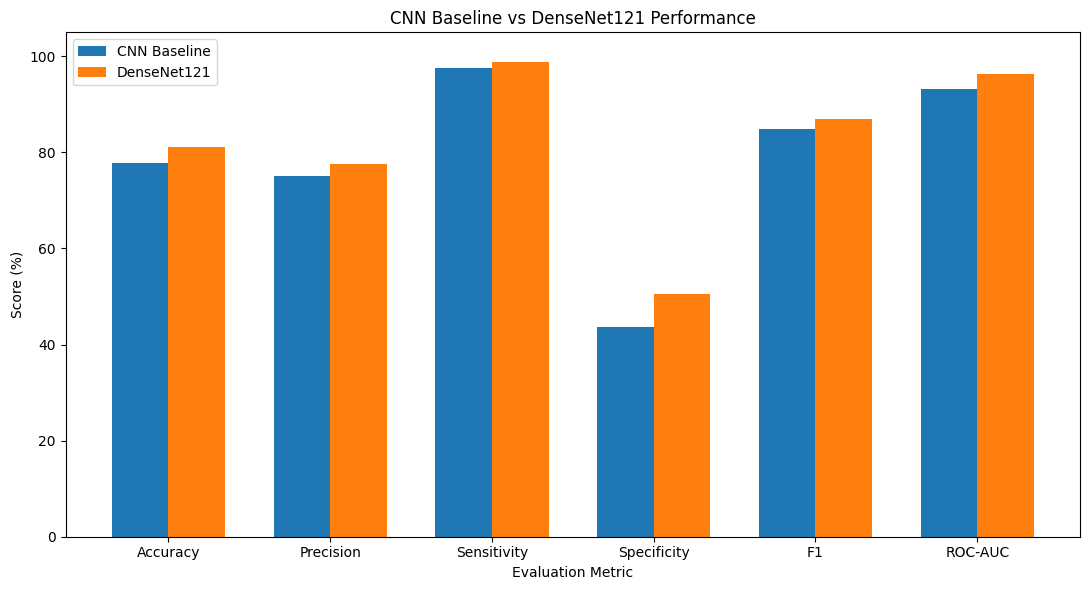

In [21]:
import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1",
    "ROC-AUC"
]

cnn_scores = [
    77.81,
    75.00,
    97.54,
    43.59,
    84.80,
    93.13
]

densenet_scores = [
    81.09,
    77.56,
    98.77,
    50.43,
    86.89,
    96.29
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    x - width/2,
    cnn_scores,
    width,
    label="CNN Baseline"
)

plt.bar(
    x + width/2,
    densenet_scores,
    width,
    label="DenseNet121"
)

plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")
plt.title("CNN Baseline vs DenseNet121 Performance")
plt.xticks(x, metrics)
plt.ylim(0, 105)
plt.legend()

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/AI_Pneumonia_Detection/models/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
print("Test generator:", "test_generator" in globals())
print("DenseNet model:", "densenet_model" in globals())
print("CNN model:", "cnn_model" in globals())

Test generator: False
DenseNet model: False
CNN model: False


In [24]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np
import matplotlib.pyplot as plt

# Paths
models_path = "/content/drive/MyDrive/AI_Pneumonia_Detection/models"
test_path = "/content/Dataset/test"

# Load saved models
cnn_model = load_model(
    f"{models_path}/cnn_baseline_best.keras"
)

densenet_model = load_model(
    f"{models_path}/densenet121_stage2_best.keras"
)

print("Models loaded successfully.")

Models loaded successfully.


In [25]:
# CNN test generator
cnn_test_datagen = ImageDataGenerator(
    rescale=1./255
)

cnn_test_generator = cnn_test_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=16,
    class_mode="binary",
    shuffle=False
)

# DenseNet test generator
densenet_test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input
)

densenet_test_generator = densenet_test_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=16,
    class_mode="binary",
    shuffle=False
)

print("Test generators created.")
print("Test images:", cnn_test_generator.samples)

Found 640 images belonging to 2 classes.
Found 640 images belonging to 2 classes.
Test generators created.
Test images: 640


Loading models...
Models loaded.
Found 640 images belonging to 2 classes.
Found 640 images belonging to 2 classes.

Test samples: 640

Generating CNN predictions...
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step

Generating DenseNet predictions...
40/40 ━━━━━━━━━━━━━━━━━━━━ 22s 122ms/step

Prediction lengths:
True labels: 640
CNN: 640
DenseNet: 640

ROC-AUC RESULTS
----------------
CNN Baseline : 0.9313
DenseNet121  : 0.9629


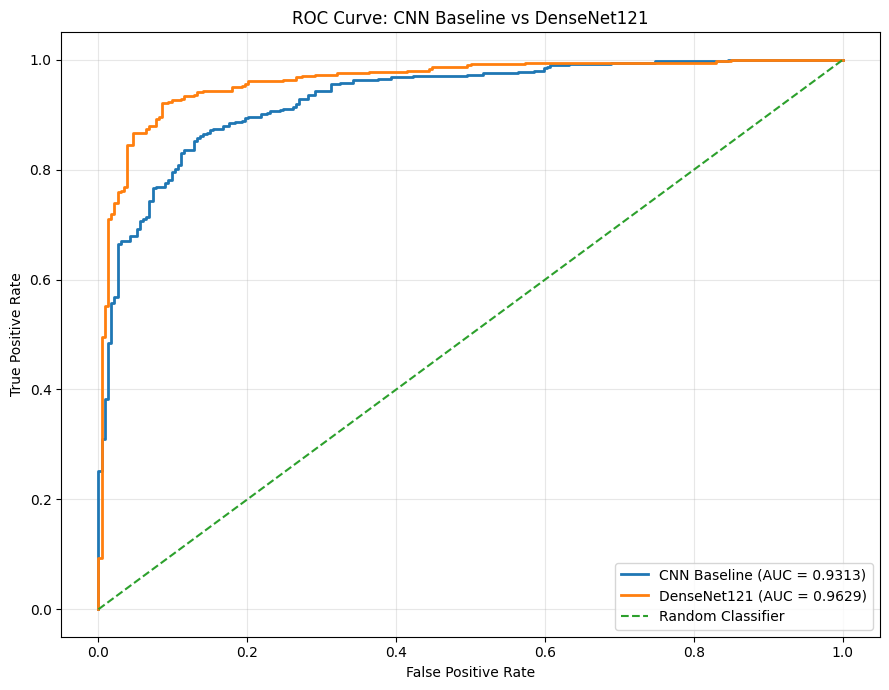


Saved to:
/content/drive/MyDrive/AI_Pneumonia_Detection/models/roc_curve_comparison.png


In [27]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import roc_curve, roc_auc_score

# ============================================================
# 1. PATHS
# ============================================================

models_path = "/content/drive/MyDrive/AI_Pneumonia_Detection/models"
test_path = "/content/Dataset/test"


# ============================================================
# 2. LOAD SAVED MODELS
# ============================================================

print("Loading models...")

cnn_model = load_model(
    f"{models_path}/cnn_baseline_best.keras"
)

densenet_model = load_model(
    f"{models_path}/densenet121_stage2_best.keras"
)

print("Models loaded.")


# ============================================================
# 3. CNN TEST GENERATOR
# ============================================================

cnn_test_datagen = ImageDataGenerator(
    rescale=1./255
)

cnn_test_generator = cnn_test_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=16,
    class_mode="binary",
    shuffle=False
)


# ============================================================
# 4. DENSENET TEST GENERATOR
# ============================================================

densenet_test_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input
)

densenet_test_generator = densenet_test_datagen.flow_from_directory(
    test_path,
    target_size=(224, 224),
    batch_size=16,
    class_mode="binary",
    shuffle=False
)


# ============================================================
# 5. TRUE LABELS
# ============================================================

y_test = cnn_test_generator.classes

print("\nTest samples:", len(y_test))


# ============================================================
# 6. GENERATE PROBABILITY PREDICTIONS
# ============================================================

print("\nGenerating CNN predictions...")

cnn_test_probs = cnn_model.predict(
    cnn_test_generator,
    verbose=1
).ravel()

print("\nGenerating DenseNet predictions...")

densenet_test_probs = densenet_model.predict(
    densenet_test_generator,
    verbose=1
).ravel()


print("\nPrediction lengths:")
print("True labels:", len(y_test))
print("CNN:", len(cnn_test_probs))
print("DenseNet:", len(densenet_test_probs))


# ============================================================
# 7. ROC CURVES
# ============================================================

cnn_fpr, cnn_tpr, _ = roc_curve(
    y_test,
    cnn_test_probs
)

densenet_fpr, densenet_tpr, _ = roc_curve(
    y_test,
    densenet_test_probs
)


# ============================================================
# 8. ROC-AUC
# ============================================================

cnn_auc = roc_auc_score(
    y_test,
    cnn_test_probs
)

densenet_auc = roc_auc_score(
    y_test,
    densenet_test_probs
)

print("\nROC-AUC RESULTS")
print("----------------")
print(f"CNN Baseline : {cnn_auc:.4f}")
print(f"DenseNet121  : {densenet_auc:.4f}")


# ============================================================
# 9. PLOT
# ============================================================

plt.figure(figsize=(9, 7))

plt.plot(
    cnn_fpr,
    cnn_tpr,
    linewidth=2,
    label=f"CNN Baseline (AUC = {cnn_auc:.4f})"
)

plt.plot(
    densenet_fpr,
    densenet_tpr,
    linewidth=2,
    label=f"DenseNet121 (AUC = {densenet_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve: CNN Baseline vs DenseNet121"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()


# ============================================================
# 10. SAVE
# ============================================================

save_path = (
    "/content/drive/MyDrive/"
    "AI_Pneumonia_Detection/models/"
    "roc_curve_comparison.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved to:")
print(save_path)

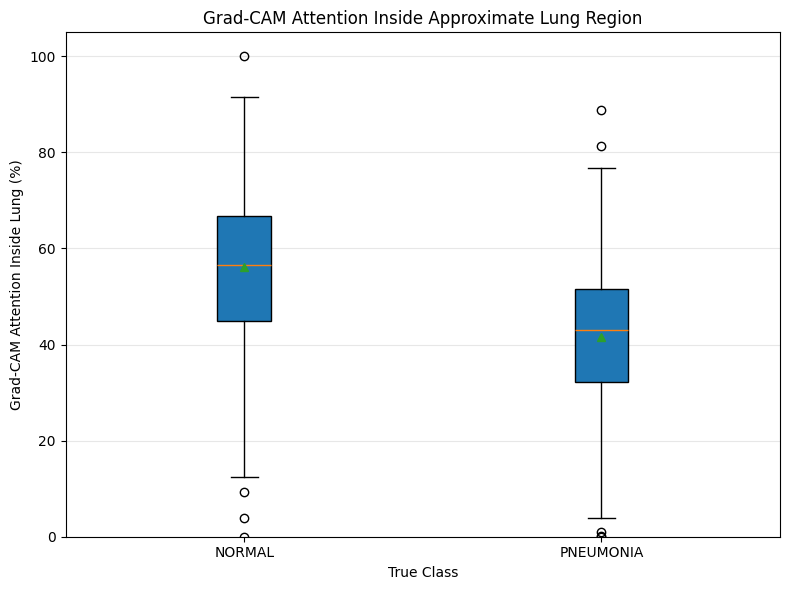

Saved to:
/content/drive/MyDrive/AI_Pneumonia_Detection/models/gradcam_attention_inside_lung_by_class.png


In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Load full Grad-CAM analysis
# ============================================================

csv_path = (
    "/content/drive/MyDrive/"
    "AI_Pneumonia_Detection/models/"
    "densenet_gradcam_lung_overlap_full.csv"
)

results_df = pd.read_csv(csv_path)

# Create readable class labels
results_df["class_name"] = results_df["true_label"].map({
    0: "NORMAL",
    1: "PNEUMONIA"
})

# ============================================================
# Plot
# ============================================================

normal_attention = results_df[
    results_df["true_label"] == 0
]["attention_inside_lung_pct"]

pneumonia_attention = results_df[
    results_df["true_label"] == 1
]["attention_inside_lung_pct"]

plt.figure(figsize=(8, 6))

plt.boxplot(
    [normal_attention, pneumonia_attention],
    labels=["NORMAL", "PNEUMONIA"],
    patch_artist=True,
    showmeans=True
)

plt.ylabel("Grad-CAM Attention Inside Lung (%)")
plt.xlabel("True Class")
plt.title(
    "Grad-CAM Attention Inside Approximate Lung Region"
)

plt.ylim(0, 105)
plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

save_path = (
    "/content/drive/MyDrive/"
    "AI_Pneumonia_Detection/models/"
    "gradcam_attention_inside_lung_by_class.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:")
print(save_path)

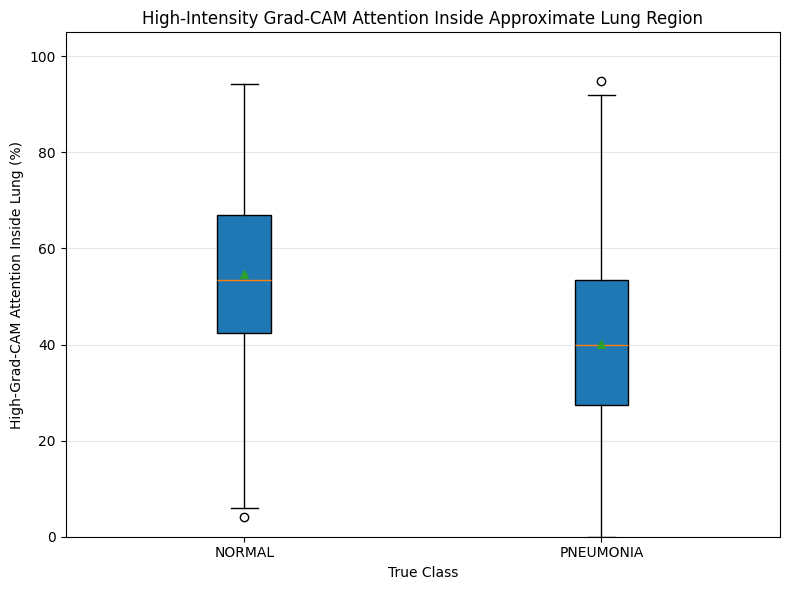

Saved to:
/content/drive/MyDrive/AI_Pneumonia_Detection/models/gradcam_high_attention_inside_lung_by_class.png


In [29]:
import matplotlib.pyplot as plt

normal_high = results_df[
    results_df["true_label"] == 0
]["high_attention_inside_lung_pct"]

pneumonia_high = results_df[
    results_df["true_label"] == 1
]["high_attention_inside_lung_pct"]

plt.figure(figsize=(8, 6))

plt.boxplot(
    [normal_high, pneumonia_high],
    labels=["NORMAL", "PNEUMONIA"],
    patch_artist=True,
    showmeans=True
)

plt.ylabel("High-Grad-CAM Attention Inside Lung (%)")
plt.xlabel("True Class")
plt.title(
    "High-Intensity Grad-CAM Attention Inside Approximate Lung Region"
)

plt.ylim(0, 105)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

save_path = (
    "/content/drive/MyDrive/"
    "AI_Pneumonia_Detection/models/"
    "gradcam_high_attention_inside_lung_by_class.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:")
print(save_path)

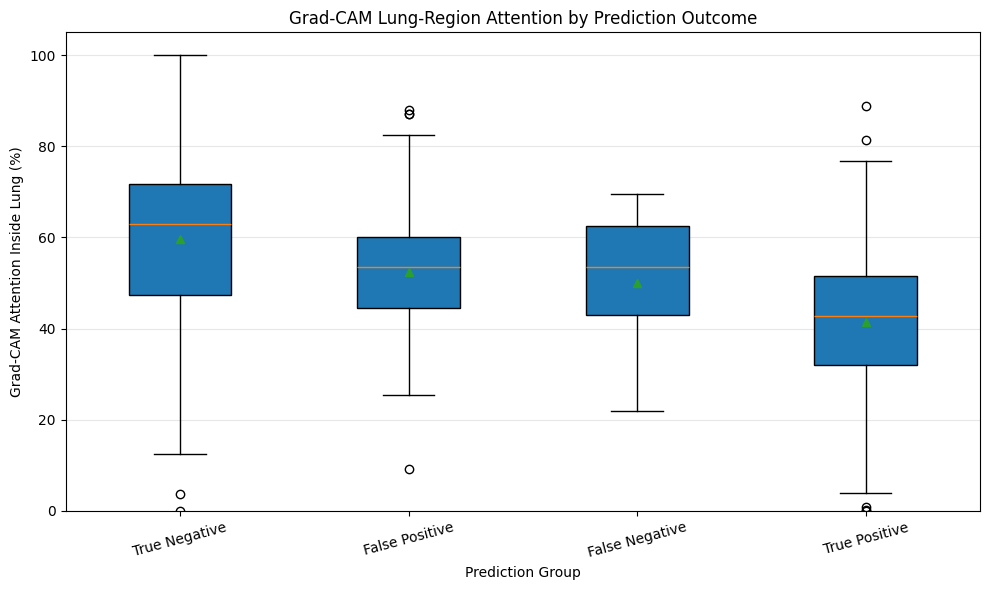

Group sizes:
prediction_group
True Negative     118
False Positive    116
False Negative      5
True Positive     401
Name: count, dtype: int64

Saved to:
/content/drive/MyDrive/AI_Pneumonia_Detection/models/gradcam_attention_by_prediction_group.png


In [30]:
# Create prediction group labels

def get_prediction_group(row):
    if row["true_label"] == 0 and row["predicted_label"] == 0:
        return "True Negative"
    elif row["true_label"] == 0 and row["predicted_label"] == 1:
        return "False Positive"
    elif row["true_label"] == 1 and row["predicted_label"] == 0:
        return "False Negative"
    else:
        return "True Positive"


results_df["prediction_group"] = results_df.apply(
    get_prediction_group,
    axis=1
)

group_order = [
    "True Negative",
    "False Positive",
    "False Negative",
    "True Positive"
]

group_data = [
    results_df[
        results_df["prediction_group"] == group
    ]["attention_inside_lung_pct"]
    for group in group_order
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    group_data,
    labels=group_order,
    patch_artist=True,
    showmeans=True
)

plt.ylabel("Grad-CAM Attention Inside Lung (%)")
plt.xlabel("Prediction Group")
plt.title(
    "Grad-CAM Lung-Region Attention by Prediction Outcome"
)

plt.xticks(rotation=15)

plt.ylim(0, 105)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

save_path = (
    "/content/drive/MyDrive/"
    "AI_Pneumonia_Detection/models/"
    "gradcam_attention_by_prediction_group.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Group sizes:")
print(
    results_df["prediction_group"].value_counts()
    .reindex(group_order)
)

print("\nSaved to:")
print(save_path)

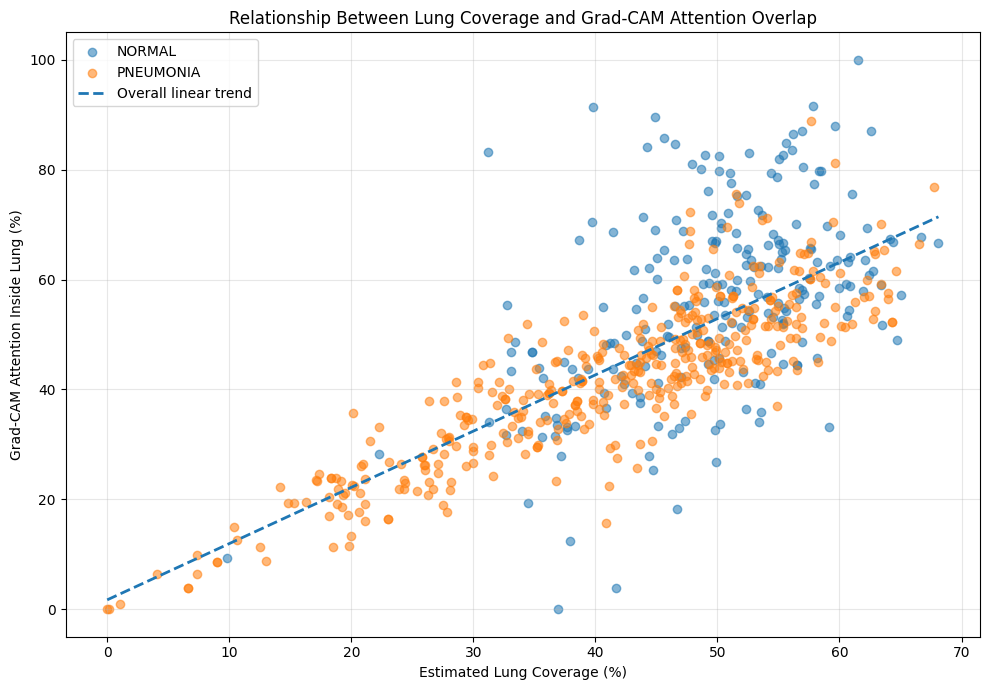

Saved to:
/content/drive/MyDrive/AI_Pneumonia_Detection/models/lung_coverage_vs_gradcam_attention.png


In [31]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 7))

# NORMAL
normal = results_df[
    results_df["true_label"] == 0
]

# PNEUMONIA
pneumonia = results_df[
    results_df["true_label"] == 1
]

plt.scatter(
    normal["lung_coverage_pct"],
    normal["attention_inside_lung_pct"],
    alpha=0.55,
    label="NORMAL"
)

plt.scatter(
    pneumonia["lung_coverage_pct"],
    pneumonia["attention_inside_lung_pct"],
    alpha=0.55,
    label="PNEUMONIA"
)

# Overall trend line
x = results_df["lung_coverage_pct"].values
y = results_df["attention_inside_lung_pct"].values

valid = np.isfinite(x) & np.isfinite(y)

slope, intercept = np.polyfit(
    x[valid],
    y[valid],
    1
)

x_line = np.linspace(
    x[valid].min(),
    x[valid].max(),
    100
)

y_line = slope * x_line + intercept

plt.plot(
    x_line,
    y_line,
    linestyle="--",
    linewidth=2,
    label="Overall linear trend"
)

plt.xlabel("Estimated Lung Coverage (%)")
plt.ylabel("Grad-CAM Attention Inside Lung (%)")

plt.title(
    "Relationship Between Lung Coverage and Grad-CAM Attention Overlap"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

save_path = (
    "/content/drive/MyDrive/"
    "AI_Pneumonia_Detection/models/"
    "lung_coverage_vs_gradcam_attention.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:")
print(save_path)

Results loaded: (640, 7)

Selected cases:
True Negative: IM-0103-0001.jpeg | prediction=0.0004 | attention=83.20%
False Positive: NORMAL2-IM-0256-0001.jpeg | prediction=0.9996 | attention=34.05%
False Negative: person119_bacteria_567.jpeg | prediction=0.0979 | attention=69.58%
True Positive: person1627_virus_2819.jpeg | prediction=1.0000 | attention=29.60%

Loading DenseNet121...
DenseNet loaded.

Loading PSPNet...
If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/pspnet_chestxray_best_model_4.pth -O /root/.torchxrayvision/models_data/pspnet_chestxray_best_model_4.pth`
[██████████████████████████████████████████████████]
PSPNet loaded.

Processing True Negative...
Done.

Processing False Positive...
Done.

Processing False Negative...
Done.

Processing True Positive...
Done.


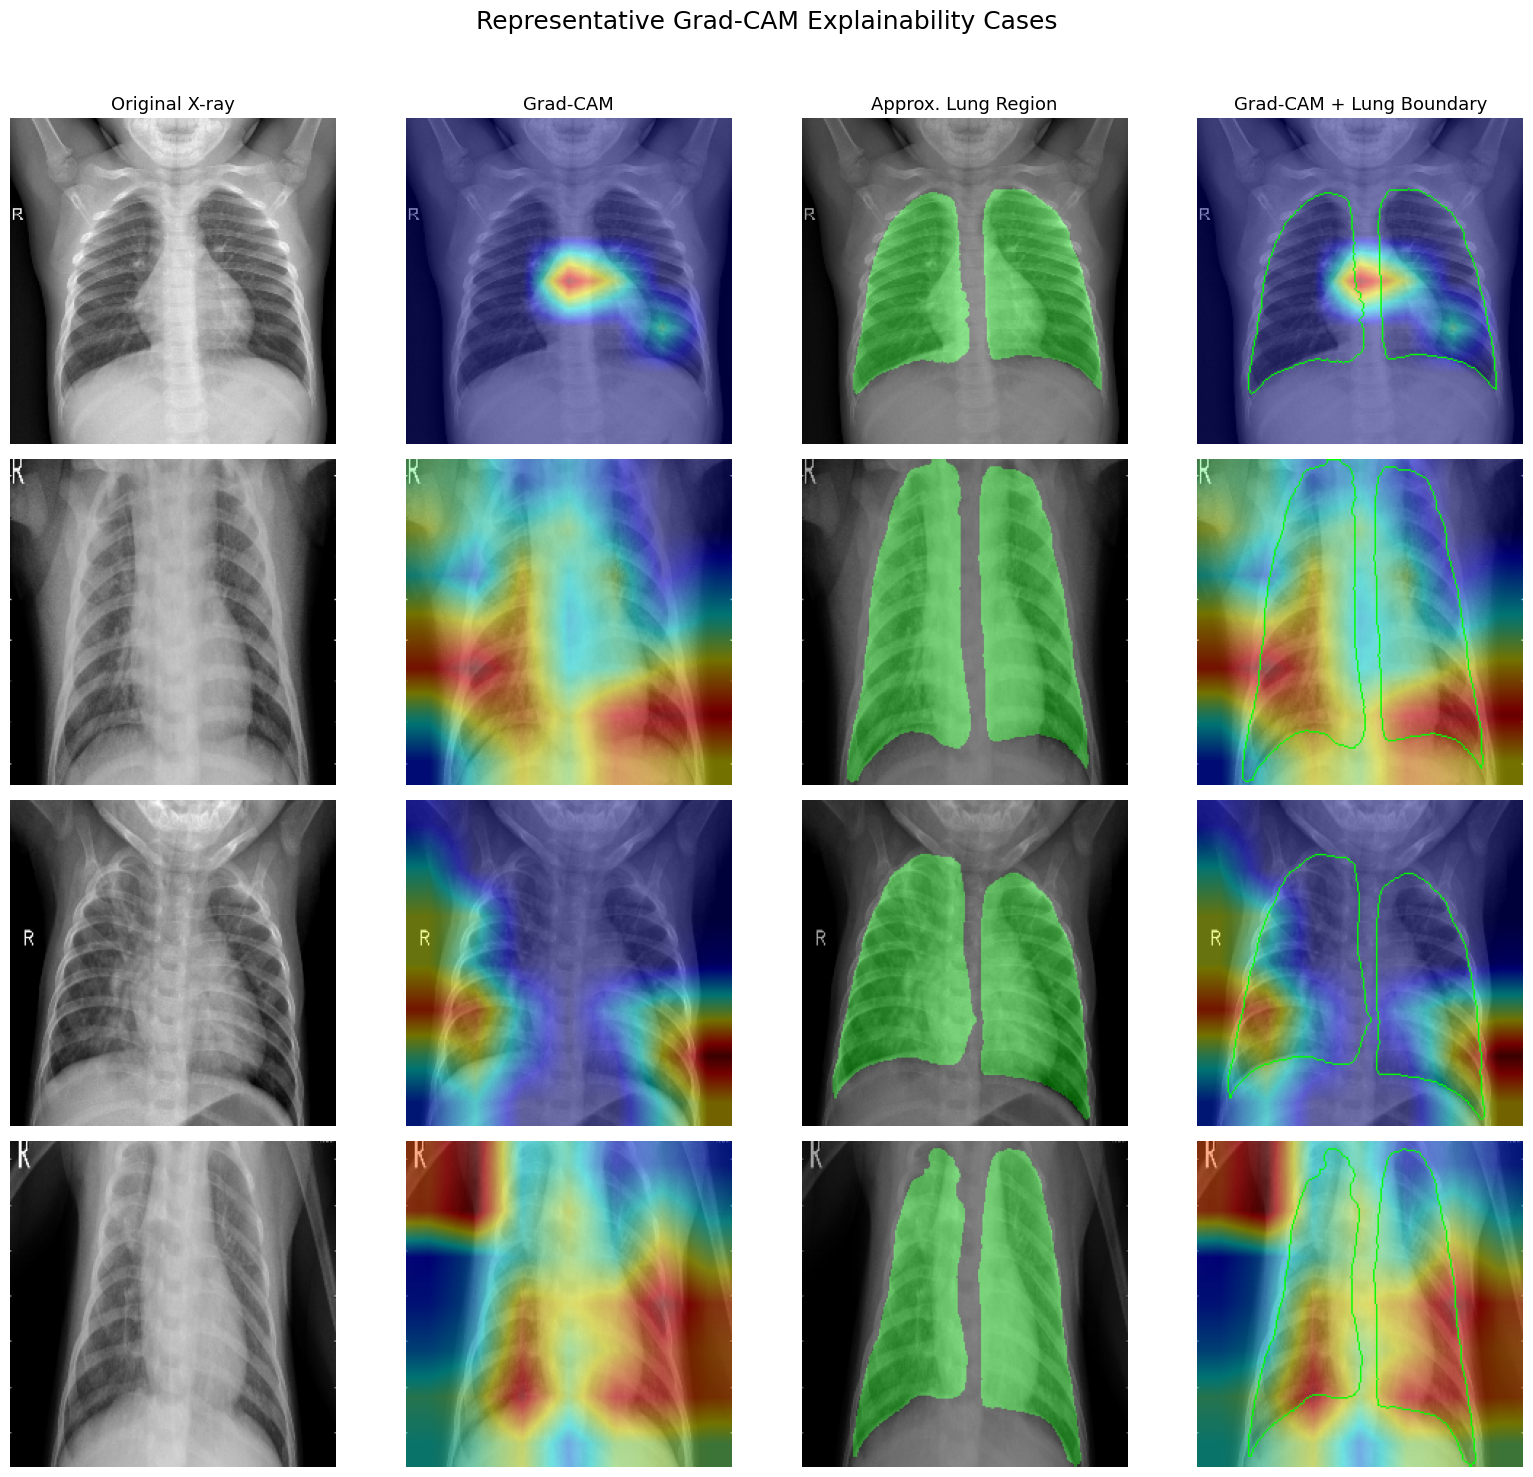


FIGURE 7 COMPLETE
Saved to:
/content/drive/MyDrive/AI_Pneumonia_Detection/models/representative_gradcam_cases.png


In [32]:
# ============================================================
# FIGURE 7 — REPRESENTATIVE GRAD-CAM EXPLAINABILITY CASES
# ============================================================

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import load_model

import torch
import torchxrayvision as xrv


# ============================================================
# 1. PATHS
# ============================================================

models_path = "/content/drive/MyDrive/AI_Pneumonia_Detection/models"
dataset_path = "/content/Dataset/test"

csv_path = (
    "/content/drive/MyDrive/"
    "AI_Pneumonia_Detection/models/"
    "densenet_gradcam_lung_overlap_full.csv"
)


# ============================================================
# 2. LOAD RESULTS
# ============================================================

results_df = pd.read_csv(csv_path)

print("Results loaded:", results_df.shape)


# ============================================================
# 3. CREATE PREDICTION GROUP
# ============================================================

def get_prediction_group(row):

    if row["true_label"] == 0 and row["predicted_label"] == 0:
        return "True Negative"

    elif row["true_label"] == 0 and row["predicted_label"] == 1:
        return "False Positive"

    elif row["true_label"] == 1 and row["predicted_label"] == 0:
        return "False Negative"

    else:
        return "True Positive"


results_df["prediction_group"] = results_df.apply(
    get_prediction_group,
    axis=1
)


# ============================================================
# 4. SELECT REPRESENTATIVE CASES
# ============================================================

# TN:
# Highest confidence NORMAL prediction
tn = results_df[
    results_df["prediction_group"] == "True Negative"
].sort_values(
    "prediction",
    ascending=True
).iloc[0]

# FP:
# Highest pneumonia probability among false positives
fp = results_df[
    results_df["prediction_group"] == "False Positive"
].sort_values(
    "prediction",
    ascending=False
).iloc[0]

# FN:
# Highest pneumonia probability among false negatives
# This gives us the most borderline / closest-to-threshold FN
fn = results_df[
    results_df["prediction_group"] == "False Negative"
].sort_values(
    "prediction",
    ascending=False
).iloc[0]

# TP:
# Highest confidence pneumonia prediction
tp = results_df[
    results_df["prediction_group"] == "True Positive"
].sort_values(
    "prediction",
    ascending=False
).iloc[0]


selected_cases = {
    "True Negative": tn,
    "False Positive": fp,
    "False Negative": fn,
    "True Positive": tp
}


print("\nSelected cases:")
for group, row in selected_cases.items():
    print(
        f"{group}: {row['image']} | "
        f"prediction={row['prediction']:.4f} | "
        f"attention={row['attention_inside_lung_pct']:.2f}%"
    )


# ============================================================
# 5. LOAD DENSENET
# ============================================================

print("\nLoading DenseNet121...")

densenet_model = load_model(
    f"{models_path}/densenet121_stage2_best.keras",
    compile=False
)

print("DenseNet loaded.")


# ============================================================
# 6. GRAD-CAM FUNCTION
# ============================================================

def make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer_name
):

    base_model = model.layers[0]

    _ = base_model(
        img_array,
        training=False
    )

    last_conv_layer = base_model.get_layer(
        last_conv_layer_name
    )

    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, backbone_output = grad_model(
            img_array,
            training=False
        )

        x = model.layers[1](
            backbone_output,
            training=False
        )

        x = model.layers[2](
            x,
            training=False
        )

        x = model.layers[3](
            x,
            training=False
        )

        predictions = model.layers[4](
            x,
            training=False
        )

        pneumonia_score = predictions[:, 0]

    grads = tape.gradient(
        pneumonia_score,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy()


# ============================================================
# 7. LOAD PSPNET
# ============================================================

print("\nLoading PSPNet...")

seg_model = xrv.baseline_models.chestx_det.PSPNet()
seg_model.eval()

print("PSPNet loaded.")


# ============================================================
# 8. GENERATE LUNG MASK
# ============================================================

def get_lung_mask(image_path):

    # Read grayscale image
    img = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    if img is None:
        raise ValueError(
            f"Could not read image: {image_path}"
        )

    # Resize for segmentation
    img = cv2.resize(
        img,
        (512, 512)
    )

    # TorchXRayVision normalization
    img_norm = xrv.datasets.normalize(
        img,
        255
    )

    img_tensor = torch.from_numpy(
        img_norm
    ).unsqueeze(0).unsqueeze(0).float()

    # PSPNet inference
    with torch.no_grad():

        output = seg_model(
            img_tensor
        )

    # Left lung = channel 4
    # Right lung = channel 5

    left_lung = torch.sigmoid(
        output[:, 4, :, :]
    )

    right_lung = torch.sigmoid(
        output[:, 5, :, :]
    )

    lung_probability = torch.maximum(
        left_lung,
        right_lung
    )

    lung_mask = (
        lung_probability[0].numpy() >= 0.5
    ).astype(np.uint8)

    return lung_mask


# ============================================================
# 9. IMAGE + GRAD-CAM PROCESSING
# ============================================================

last_conv_layer = "conv5_block16_2_conv"


def process_case(row):

    image_name = row["image"]

    true_label = int(row["true_label"])

    # Determine folder
    if true_label == 0:
        class_folder = "NORMAL"
    else:
        class_folder = "PNEUMONIA"

    image_path = os.path.join(
        dataset_path,
        class_folder,
        image_name
    )

    if not os.path.exists(image_path):

        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    # --------------------------------------------------------
    # Original image
    # --------------------------------------------------------

    original_gray = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    original_gray = cv2.resize(
        original_gray,
        (224, 224)
    )

    original_rgb = cv2.cvtColor(
        original_gray,
        cv2.COLOR_GRAY2RGB
    )

    # --------------------------------------------------------
    # DenseNet preprocessing
    # --------------------------------------------------------

    img_rgb = original_rgb.astype(
        np.float32
    )

    img_input = np.expand_dims(
        img_rgb,
        axis=0
    )

    img_input = tf.keras.applications.densenet.preprocess_input(
        img_input
    )

    # --------------------------------------------------------
    # Grad-CAM
    # --------------------------------------------------------

    heatmap = make_gradcam_heatmap(
        img_input,
        densenet_model,
        last_conv_layer
    )

    heatmap_resized = cv2.resize(
        heatmap,
        (224, 224)
    )

    # --------------------------------------------------------
    # Lung mask
    # --------------------------------------------------------

    lung_mask = get_lung_mask(
        image_path
    )

    lung_mask_resized = cv2.resize(
        lung_mask,
        (224, 224),
        interpolation=cv2.INTER_NEAREST
    )

    # --------------------------------------------------------
    # Grad-CAM overlay
    # --------------------------------------------------------

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    heatmap_color = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    heatmap_color = cv2.cvtColor(
        heatmap_color,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original_rgb,
        0.55,
        heatmap_color,
        0.45,
        0
    )

    # --------------------------------------------------------
    # Lung mask overlay
    # --------------------------------------------------------

    mask_rgb = np.zeros_like(
        original_rgb
    )

    mask_rgb[:, :, 1] = (
        lung_mask_resized * 255
    )

    lung_overlay = cv2.addWeighted(
        original_rgb,
        0.65,
        mask_rgb,
        0.35,
        0
    )

    # --------------------------------------------------------
    # Combined Grad-CAM + lung boundary
    # --------------------------------------------------------

    combined = overlay.copy()

    contours, _ = cv2.findContours(
        lung_mask_resized,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        combined,
        contours,
        -1,
        (0, 255, 0),
        1
    )

    return {
        "original": original_rgb,
        "gradcam": overlay,
        "lung": lung_overlay,
        "combined": combined
    }


# ============================================================
# 10. PROCESS ALL FOUR CASES
# ============================================================

processed_cases = {}

for group, row in selected_cases.items():

    print(f"\nProcessing {group}...")

    processed_cases[group] = process_case(
        row
    )

    print("Done.")


# ============================================================
# 11. CREATE FINAL FIGURE
# ============================================================

groups = [
    "True Negative",
    "False Positive",
    "False Negative",
    "True Positive"
]

titles = [
    "Original X-ray",
    "Grad-CAM",
    "Approx. Lung Region",
    "Grad-CAM + Lung Boundary"
]


fig, axes = plt.subplots(
    4,
    4,
    figsize=(16, 16)
)


for row_idx, group in enumerate(groups):

    images = processed_cases[group]

    row_data = selected_cases[group]

    prediction = row_data["prediction"]

    true_label = int(
        row_data["true_label"]
    )

    true_name = (
        "NORMAL"
        if true_label == 0
        else "PNEUMONIA"
    )

    for col_idx, title in enumerate(titles):

        if col_idx == 0:
            img = images["original"]

        elif col_idx == 1:
            img = images["gradcam"]

        elif col_idx == 2:
            img = images["lung"]

        else:
            img = images["combined"]

        axes[row_idx, col_idx].imshow(
            img,
            cmap="gray"
        )

        axes[row_idx, col_idx].axis(
            "off"
        )

        if row_idx == 0:
            axes[row_idx, col_idx].set_title(
                title,
                fontsize=13
            )

    axes[row_idx, 0].set_ylabel(
        f"{group}\n"
        f"True: {true_name}\n"
        f"Pneumonia probability: {prediction:.3f}",
        fontsize=11
    )


fig.suptitle(
    "Representative Grad-CAM Explainability Cases",
    fontsize=18,
    y=0.92
)

plt.tight_layout(
    rect=[0, 0, 1, 0.90]
)


# ============================================================
# 12. SAVE
# ============================================================

save_path = (
    "/content/drive/MyDrive/"
    "AI_Pneumonia_Detection/models/"
    "representative_gradcam_cases.png"
)

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n====================================")
print("FIGURE 7 COMPLETE")
print("====================================")
print("Saved to:")
print(save_path)